# **Modelos candidatos — protocolo en el panel de 8 municipios y referencias**

Notebook del Entregable 3. **Esta primera etapa cubre sólo el protocolo y las referencias**:
reglas fijadas antes de ejecutar (sección 1), carga sin el bloque final (2), motor de
backtesting (3), métricas (4), control cruzado del motor contra `linea_base.ipynb` (5) y las
referencias en el panel (6). Los modelos candidatos (GLM Poisson, GLM binomial negativa,
XGBoost) se agregan en una etapa posterior, **sin modificar** lo que está acá.

**El bloque final (2025-02-06 → 2025-12-31) no se lee en ningún código de este notebook.** Toda
lectura del panel descarta las filas posteriores a 2025-02-05 en el mismo paso, y un `assert`
verifica que no quedó ninguna.

**Fase 2 (19/10/2026).** Las secciones 7 a 9 agregan la experimentación con los candidatos (pasos A, B y C)
a continuación de la sección 6, sin modificar las secciones 0 a 6, la adenda ni las precisiones de la
fase 2. «Estado y artefactos» pasó a ser la sección 10.

## 0. Entorno

Igual que `linea_base.ipynb`: lee `requirements.txt` en vivo y **detiene la ejecución** si la
versión de Python o la de alguna dependencia directa difiere.

In [1]:
# Detiene la ejecución si el entorno no coincide con requirements.txt. No es un aviso.
import platform
import re
from pathlib import Path
import importlib.metadata as importlib_metadata

_cwd = Path.cwd()
if (_cwd / "requirements.txt").exists():
    _RAIZ_CHK = _cwd
elif (_cwd.parent / "requirements.txt").exists():
    _RAIZ_CHK = _cwd.parent
else:
    raise FileNotFoundError("No se encuentra requirements.txt para verificar el entorno.")

_req_texto = (_RAIZ_CHK / "requirements.txt").read_text(encoding="utf-8")

_m_py = re.search(r"#\s*Python\s+(\d+\.\d+\.\d+)", _req_texto)
if not _m_py:
    raise RuntimeError("No se encontró la versión de Python esperada en requirements.txt.")
PYTHON_ESPERADO = _m_py.group(1)

DEPENDENCIAS_ESPERADAS = {}
for _linea in _req_texto.splitlines():
    _sin_comentario = _linea.split("#", 1)[0].strip()
    _m = re.match(r"^([A-Za-z0-9_.\-]+)==([A-Za-z0-9_.\-]+)$", _sin_comentario)
    if _m:
        DEPENDENCIAS_ESPERADAS[_m.group(1).lower()] = _m.group(2)

python_actual = platform.python_version()
_errores = []
if python_actual != PYTHON_ESPERADO:
    _errores.append(f"Python: se esperaba {PYTHON_ESPERADO}, hay {python_actual}")

for _paquete, _version_esperada in DEPENDENCIAS_ESPERADAS.items():
    try:
        _version_actual = importlib_metadata.version(_paquete)
    except importlib_metadata.PackageNotFoundError:
        _errores.append(f"{_paquete}: no está instalado (se esperaba {_version_esperada})")
        continue
    if _version_actual != _version_esperada:
        _errores.append(f"{_paquete}: se esperaba {_version_esperada}, hay {_version_actual}")

if _errores:
    _mensaje = ("El entorno no coincide con requirements.txt (instalar con "
                "`pip install -r requirements.txt -c requirements-lock.txt`):\n  - "
                + "\n  - ".join(_errores))
    raise RuntimeError(_mensaje)

print(f"Entorno OK — Python {python_actual}, {len(DEPENDENCIAS_ESPERADAS)} dependencias "
      f"directas verificadas contra requirements.txt (ninguna diferencia).")

Entorno OK — Python 3.13.2, 18 dependencias directas verificadas contra requirements.txt (ninguna diferencia).


## 1. Reglas fijadas antes de ejecutar

> **Esta celda no se modifica después de ver resultados.** Cualquier cambio posterior se
> registra aparte, con fecha y motivo, en el documento acompañante.

**Lista cerrada de modelos**

- *Referencias.* (i) Media constante global. (ii) **L0**: promedio de lo observado 7, 14, 21 y 28
  días antes; su ventana se revisa con 2, 4 y 8 semanas. (iii) **L1 en el panel**: nivel del
  municipio × factor de calendario agregado de 8 niveles (lunes a domingo, más feriado); es el
  modelo M2 de `diagnostico_municipios.ipynb`.
- *Candidatos* (se agregan en una etapa posterior). GLM Poisson, GLM binomial negativa y XGBoost
  con `objective="count:poisson"`.

**Árbol de decisión: retirado antes de ejecutar.** En el Entregable 2 no extrapoló la
tendencia, y XGBoost con pérdida Poisson es la extensión de la misma familia.

**Conjuntos de variables, anidados**

| Conjunto | Contenido |
| --- | --- |
| (0) | sin exógenas: municipio + nivel reciente + rezagos 7/14/21/28 |
| (a) | municipio + calendario de 8 niveles |
| (b) | (a) + término propio de calendario para el municipio A |
| (c) | (b) + nivel reciente (28/56/91 días) |

**El conjunto (d) (= (c) + lluvia) se eliminó de la lista antes de ejecutar** (decisión del
equipo, 2026-10-14). Motivo: la lluvia del día a predecir no está disponible con un horizonte de
7 días (sólo existiría un pronóstico), y el diagnóstico no le encontró aporte fuera de muestra
(`diagnostico_municipios.ipynb`, §7.5). La lluvia no figura en `src/variables.py`.

**Grilla de XGBoost.** `max_depth` ∈ {2, 3, 4} × `n_estimators` ∈ {100, 300} ×
`learning_rate` ∈ {0.05, 0.1}. El resto de los parámetros, fijos y declarados.

**Ventanas de entrenamiento.** Expansiva; deslizante de 364, 546 y 728 días.

**Orden de la experimentación**

- **A.** Conjuntos con GLM Poisson y XGBoost por defecto, en ventana expansiva.
- **B.** Grilla de XGBoost y ajuste de la binomial negativa sobre el conjunto elegido.
- **C.** Ventanas para los dos mejores candidatos.

**Regla de selección**

1. Desvianza de Poisson media en validación.
2. Empate: candidatos a menos de 1 error estándar del mejor, con el error estándar calculado
   sobre los 47 cortes.
3. Entre empatados, el más simple y explicable (GLM antes que XGBoost; menos variables antes
   que más).
4. Desempate por estabilidad (peor municipio, dispersión entre semanas) y luego por calibración
   (total predicho / observado).

**Binomial negativa.** Se reporta la dispersión de Pearson del GLM Poisson y el α estimado. Su
papel declarado son los intervalos de predicción y la inferencia sobre coeficientes, no mejorar
la desvianza.

**Sesgo declarado.** La búsqueda de hiperparámetros y la selección usan los mismos 47 cortes; el
desempeño del ganador en validación es optimista.

**Protocolo común (de `linea_base.ipynb`, sin cambios).** Horizonte de 7 días, 47 cortes de
origen móvil, reentrenamiento en cada corte; desvianza de Poisson media como métrica principal.

## Adenda a la sección 1 — Precisiones fijadas el 19/10/2026, después de la fase 1 y antes de ejecutar cualquier candidato

> **La celda de la sección 1 no se modificó.** Este bloque registra, con fecha y motivo, cinco
> precisiones del plan (cada una con su decisión) que la sección 1 dejó abiertas o sin escribir.
> Se fijaron con las referencias de la fase 1 ya evaluadas y **antes de ejecutar cualquier
> candidato** (GLM Poisson, GLM binomial negativa, XGBoost). La lista cerrada de modelos, los
> conjuntos (0), (a), (b) y (c), la grilla de XGBoost, las ventanas, el orden A → B → C y la regla
> de selección de la sección 1 siguen como estaban.

1. **L0 que pasa a la comparación: 8 semanas** (D17). La sección 1 dejó la ventana de L0 «a revisar con
   2, 4 y 8 semanas» sin una regla para elegir. La elección se hizo **después de fijar la lista y
   mirando los 47 cortes de validación**: desvianza de Poisson media de **1,3626** con 8 semanas,
   contra 1,5210 con 4 semanas (la del Entregable 2) y 2,4384 con 2 semanas
   (`experiments/modelos_candidatos/tablas/05_referencias_globales.csv`). Es una elección
   **informada por la validación**, no una regla previa a los resultados. La media constante marca
   1,3967 (misma tabla) y su error estándar sobre los 47 cortes es 0,0447
   (`tablas/08_referencias_error_estandar_y_estabilidad.csv`): L0 de 8 semanas queda por debajo
   de ella por 0,0341, es decir, **a menos de 1 error estándar**. El bloque final no intervino.
2. **Nivel reciente del conjunto (0)** (D18). N ∈ {28, 56, 91} días, elegido en el paso A por la
   desvianza de Poisson media en validación, **por separado en cada familia** (GLM Poisson y
   XGBoost), igual que en el conjunto (c).
3. **XGBoost en el paso A** (D19). `max_depth=3`, `n_estimators=300`, `learning_rate=0.05`; el resto de
   los parámetros, fijos y declarados en el código; semilla fija.
4. **Elección del conjunto por familia** (GLM y XGBoost) (D20). Entre (a), (b) y (c), con la regla de
   1 error estándar de la sección 1 y el orden de simplicidad a < b < c. El conjunto (0) se
   reporta para el objetivo 1.2.2 y solo reemplaza al elegido si lo mejora por más de 1 error
   estándar.
5. **Binomial negativa: NB2** (D27 y D28). Varianza μ + αμ², con α **estimado por máxima verosimilitud en
   cada corte**: `statsmodels.discrete.discrete_model.NegativeBinomial` con
   `loglike_method="nb2"` (parámetro y valor verificados en la firma y el docstring de la clase de
   statsmodels 0.14.6, la versión instalada). La familia `NegativeBinomial` del GLM
   (`statsmodels.genmod.families`) deja α fijo (1,0 si no se le pasa), por eso no se usa como
   estimador principal. **Plan B (D28):** si NB2 por máxima verosimilitud no converge
   en un corte, se reporta y en ese corte se usa el GLM NB con α estimado por momentos en el
   mismo corte: regresión auxiliar sin intercepto de ((y − μ)² − y)/μ sobre μ, con μ del GLM
   Poisson ajustado en el entrenamiento de ese corte (Cameron y Trivedi, 1990).
6. **Criterio de convergencia de NB2** (D29) — *agregado el 19/10/2026 en el fix de la ronda 2, antes de ejecutar candidatos (D29).*
   Sexta precisión, posterior a las cinco anteriores (que no se modifican). NB2 se ajusta con
   `method="newton"` y `maxiter=100`. Un corte cuenta como **no convergido** si
   `mle_retvals["converged"]` es `False`, si se emite un `ConvergenceWarning` o si α no es finito o
   no es positivo; en ese caso se aplica el plan B (D28) del ítem 5.

## Precisiones de la fase 2, fijadas el 19/10/2026 antes de ejecutar candidatos

> **Ni la sección 1 ni la adenda se modificaron.** Este bloque agrega cinco precisiones (D31 a D34 y la
> del ítem 5) que la fase 2 necesita y que ninguna de las dos cubre. Se fijaron **antes de ejecutar cualquier candidato**
> (GLM Poisson, binomial negativa, XGBoost), con las referencias de la fase 1 como único resultado visto.

1. **Matriz de indicadoras** (D31). La misma matriz para GLM y XGBoost: **8 columnas de municipio, sin
   constante** (cada municipio con su propio intercepto); **calendario con 7 columnas, lunes como
   referencia**; **término de A con 7 columnas `a_x_*`, sin `a_x_lunes`** (con las 8 columnas el término
   sería colineal con la indicadora de A, como advierte `src/variables.py`). En el GLM la
   parametrización no cambia las predicciones; en XGBoost sí, y así A queda en una sola columna.
2. **Error estándar del ítem 4 de la adenda** (D32): el de (0). El conjunto (0) reemplaza al elegido
   entre (a), (b) y (c) **solo si desv(elegido) − desv(0) > EE(0)**, con EE(0) el error estándar de (0)
   sobre los 47 cortes. Es coherente con el paso 2 de la regla de selección, donde el error estándar es
   el del mejor.
3. **Registro de experimentos** (D33). `experiments/modelos_candidatos/registro_experimentos.csv` se
   **reescribe en cada ejecución** del notebook, con todas las configuraciones evaluadas en esa
   ejecución (incluidos los resultados negativos) y su fecha y hora. El notebook es determinista; el
   historial queda en git, con un commit en cada parada (después de los pasos A, B y C).
4. **Forma de las variables** (D34). En (0) y en (c), el nivel reciente entra como
   **log(nivel_reciente_N)** —con coeficiente 1 la predicción escala con el nivel reciente— y los
   **rezagos 7/14/21/28 como conteos crudos** (hay ceros: log(y) no está definido). En XGBoost la
   transformación logarítmica no cambia los árboles. Una verificación detiene la ejecución si algún nivel
   reciente vale 0 (el logaritmo no estaría definido).
5. **Parámetros de XGBoost fuera de D19**: valores por defecto de xgboost 3.4.1 (`tree_method="hist"`,
   `subsample=1`, `colsample_bytree=1`, `min_child_weight=1`, `reg_lambda=1`), más `random_state=SEMILLA`
   y `n_jobs=1` para que los resultados sean deterministas.

## Precisiones del paso B, fijadas el 19/10/2026 antes de ejecutarlo

> **Nada de lo anterior se modificó** (sección 1, adenda, precisiones de la fase 2). Este bloque precisa cómo se aplican los pasos
> 3 y 4 de la regla de selección dentro de una familia con las mismas variables, caso que la sección 1 no resuelve. Se fijó con
> los resultados del paso A ya vistos y **antes de ejecutar el paso B**. **Vale también para el paso C.**

1. **Simplicidad entre GLM Poisson y NB2** (D36). Con la misma matriz, **GLM Poisson es más simple que NB2** (un parámetro menos:
   NB2 con α → 0 es Poisson). Si empatan a menos de 1 error estándar, gana Poisson. Cómo se construyen los intervalos de
   predicción se decide en la fase 3.
2. **Simplicidad entre combinaciones de XGBoost** (D37). Entre combinaciones empatadas, más simple = **menor `max_depth`** y, a
   igual profundidad, **menor `n_estimators`**. `learning_rate` no cuenta como complejidad: si dos combinaciones solo difieren
   en él, decide el paso 4.
3. **Paso 4, lexicográfico con tolerancia de 1 EE** (D38). Entre las empatadas que siguen sin separarse: pasan las que tienen una
   desvianza del peor municipio **a menos de 1 EE de la mejor en ese criterio**. El EE es el del peor municipio de esa mejor
   configuración, calculado sobre los 47 cortes (como en `tablas/12`). Entre ellas gana la de **menor desvío entre cortes**; si
   empatan, la de **menor |total pred./obs. − 1|**.

## Precisiones del paso C, fijadas el 19/10/2026 con los resultados de los pasos A y B ya vistos

> **Nada de lo anterior se modificó** (sección 1, adenda, precisiones de la fase 2 y del paso B). Este bloque se fijó **después de ver
> los resultados de los pasos A y B** (secciones 7 y 8) y **antes de ejecutar el paso C**.

1. **XGBoost que pasa al paso C** (D39). Se mantiene la XGBoost elegida por la regla en el paso B (`max_depth=2`, `n_estimators=100`,
   `learning_rate=0.1`), **aunque su desvianza media sea peor que la de L1** (sección 8.1). La mejor combinación de la grilla en
   desvianza (`max_depth=4`, `n_estimators=300`, `learning_rate=0.05`) se reporta como referencia y **no se ejecuta en el paso C**.
2. **La ventana no cuenta como complejidad** (D40). En el paso 3 de la regla solo se ordena por familia (GLM antes que XGBoost). Entre
   ventanas de la misma familia que sigan empatadas, decide el paso 4 (D38).

## Importación de librerías y configuración

In [2]:
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import statsmodels
import xgboost
from sklearn.metrics import mean_poisson_deviance, mean_absolute_error, mean_squared_error

# Mismo aviso y mismo motivo que en pytest.ini: lo emite pandas 2.3.3 con numpy 2.5.2 en cada pd.Timedelta
# (también en las llamadas de src/variables.py); no indica un error del proyecto. Se filtra solo este aviso.
warnings.filterwarnings("ignore", message="The .generic. unit for NumPy timedelta", category=DeprecationWarning)

RAIZ = _RAIZ_CHK
sys.path.insert(0, str(RAIZ))
from src import datos, variables as var      # única implementación de las variables y de la carga del panel

SEMILLA = 20260910      # la de linea_base.ipynb y diagnostico_municipios.ipynb
np.random.seed(SEMILLA)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

DIR_EXPERIMENTO = RAIZ / "experiments" / "modelos_candidatos"
DIR_TABLAS = DIR_EXPERIMENTO / "tablas"
DIR_FIGURAS = DIR_EXPERIMENTO / "figuras"
DIR_TABLAS.mkdir(parents=True, exist_ok=True)
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)


def guardar_tabla(df, nombre):
    "Escribe un CSV (UTF-8) en experiments/modelos_candidatos/tablas y devuelve el DataFrame."
    ruta = DIR_TABLAS / nombre
    df.to_csv(ruta, index=False, encoding="utf-8")
    print("  guardado:", ruta.relative_to(RAIZ), f"({len(df)} filas)")
    return df


def guardar_figura(fig, nombre):
    ruta = DIR_FIGURAS / nombre
    fig.savefig(ruta, bbox_inches="tight")
    print("  guardado:", ruta.relative_to(RAIZ))


entorno = pd.DataFrame({
    "componente": ["python", "pandas", "numpy", "scipy", "matplotlib", "scikit-learn", "statsmodels", "xgboost"],
    "version": [python_actual, pd.__version__, np.__version__, __import__("scipy").__version__,
                matplotlib.__version__, sklearn.__version__, statsmodels.__version__, xgboost.__version__],
})
guardar_tabla(entorno, "00_entorno.csv")

  guardado: experiments\modelos_candidatos\tablas\00_entorno.csv (8 filas)


,componente,version
0,python,3.13.2
1,pandas,2.3.3
2,numpy,2.5.2
3,scipy,1.18.1
4,matplotlib,3.11.1
5,scikit-learn,1.9.0
6,statsmodels,0.14.6
7,xgboost,3.4.1


## 2. Carga del panel, sin el bloque final

`data/processed/panel_diario_montevideo.csv`, leído por `src.datos.cargar_panel_desarrollo()`: lee
por tramos y **recorta cada tramo a `fecha <= 2025-02-05` antes de acumularlo**: ninguna
fila del test se conserva ni se acumula; cada tramo se lee y se filtra antes de acumularse. El límite sale del calendario (80 % de los 1.645 días del período
2021-07-01 → 2025-12-31 = 1.316 días), no de los datos.

Particiones del desarrollo (las de `linea_base.ipynb`): **987 días de entrenamiento inicial** y
**329 de validación**, en los 8 municipios. Los cortes de validación arrancan en el día 988.

In [3]:
panel = datos.cargar_panel_desarrollo()

# Verificaciones que detienen la ejecución si algo falla (no son avisos).
ULTIMO = datos.ULTIMO_DIA_DESARROLLO
FECHAS = pd.DatetimeIndex(sorted(panel["fecha"].unique()))
INICIAL = int(round(0.75 * datos.N_DESARROLLO))            # 987 días de entrenamiento inicial
N_VALIDACION = datos.N_DESARROLLO - INICIAL                # 329 días de validación
HORIZONTE, PASO = var.HORIZONTE, 7
ORIGENES = [FECHAS[i] for i in range(INICIAL, len(FECHAS), PASO)]

verif = [
    ("límite del desarrollo = 2025-02-05 (sale del calendario)", str(ULTIMO.date()) == "2025-02-05"),
    ("ninguna fila posterior a 2025-02-05", not (panel["fecha"] > pd.Timestamp("2025-02-05")).any()),
    ("el panel llega al último día de desarrollo", panel["fecha"].max() == ULTIMO),
    ("8 municipios", panel["zona_id"].nunique() == 8),
    ("10.528 filas (1.316 días × 8)", len(panel) == 1316 * 8),
    ("sin pares (fecha, municipio) repetidos", not panel.duplicated(["fecha", "zona_id"]).any()),
    ("calendario diario sin huecos", FECHAS.equals(pd.date_range(datos.FECHA_INICIO, ULTIMO, freq="D"))),
    ("objetivo sin nulos, entero y no negativo", bool(panel["n_siniestros"].notna().all() and (panel["n_siniestros"] >= 0).all())),
    ("987 días de entrenamiento inicial y 329 de validación", (INICIAL, N_VALIDACION) == (987, 329)),
    ("47 cortes de 7 días", len(ORIGENES) == 47),
    ("el último corte termina en el último día de desarrollo", ORIGENES[-1] + pd.Timedelta(days=HORIZONTE - 1) == ULTIMO),
]
tabla_verif = pd.DataFrame(verif, columns=["verificación", "ok"])
print(tabla_verif.to_string(index=False))
assert tabla_verif["ok"].all(), "Alguna verificación de integridad falló."
guardar_tabla(tabla_verif, "01_verificacion_integridad.csv")

particiones = pd.DataFrame({
    "bloque": ["entrenamiento inicial", "validación (47 cortes de 7 días)", "bloque final (test)"],
    "desde": [str(FECHAS[0].date()), str(FECHAS[INICIAL].date()), str(datos.PRIMER_DIA_TEST.date())],
    "hasta": [str(FECHAS[INICIAL - 1].date()), str(FECHAS[-1].date()), "2025-12-31"],
    "dias": [INICIAL, N_VALIDACION, "no cargado"],
})
guardar_tabla(particiones, "02_particiones.csv")
particiones

                                            verificación   ok
límite del desarrollo = 2025-02-05 (sale del calendario) True
                     ninguna fila posterior a 2025-02-05 True
              el panel llega al último día de desarrollo True
                                            8 municipios True
                           10.528 filas (1.316 días × 8) True
                  sin pares (fecha, municipio) repetidos True
                            calendario diario sin huecos True
                objetivo sin nulos, entero y no negativo True
   987 días de entrenamiento inicial y 329 de validación True
                                     47 cortes de 7 días True
  el último corte termina en el último día de desarrollo True
  guardado: experiments\modelos_candidatos\tablas\01_verificacion_integridad.csv (11 filas)
  guardado: experiments\modelos_candidatos\tablas\02_particiones.csv (3 filas)


,bloque,desde,hasta,dias
0,entrenamiento inicial,2021-07-01,2024-03-13,987
1,validación (47 cortes de 7 días),2024-03-14,2025-02-05,329
2,bloque final (test),2025-02-06,2025-12-31,no cargado


## 3. Motor de backtesting

- **47 cortes** de horizonte 7, **origen móvil**, **reentrenamiento en cada corte**. El origen es el
  primer día a predecir; lo que se conoce es todo lo anterior (`fecha < origen`).
- **Parámetro de ventana.** `ventana=None` es la expansiva (todo lo anterior al origen);
  `ventana=N` es la deslizante de los últimos N días. En esta etapa sólo se usa la expansiva.
- **El modelo no puede mirar el futuro ni por descuido.** A cada modelo se le entrega una *vista*:
  el panel hasta el último día del horizonte, con el **objetivo de los días ≥ origen reemplazado
  por NaN** (el calendario `tipo_dia` sí se conserva, se conoce de antemano). El objetivo real se
  usa sólo para evaluar, después de predecir.
- **Todo lo que aprende de los datos se estima con la ventana de entrenamiento del corte**, usando
  `src/variables.py` (rezagos, nivel del municipio, calendario).
- Se **guardan las predicciones** por corte, día y municipio: la regla del error estándar las necesita.

Un modelo es una función `modelo(vista, origen, ventana) -> DataFrame[fecha, zona_id, pred]`.

In [4]:
def backtest(panel, modelo, ventana=None, origenes=ORIGENES, horizonte=HORIZONTE):
    "Predicciones de `modelo` en cada corte. Devuelve: corte, origen, fecha, zona_id, n_siniestros, pred."
    salida = []
    for corte, origen in enumerate(origenes, start=1):
        fin = origen + pd.Timedelta(days=horizonte)
        vista = panel[panel["fecha"] < fin].copy()
        vista.loc[vista["fecha"] >= origen, "n_siniestros"] = np.nan      # el futuro no se entrega
        p = modelo(vista, origen, ventana)
        real = panel[(panel["fecha"] >= origen) & (panel["fecha"] < fin)][["fecha", "zona_id", "n_siniestros"]]
        m = real.merge(p, on=["fecha", "zona_id"], how="left", validate="one_to_one")
        assert len(p) == len(real) and m["pred"].notna().all(), f"predicciones faltantes en el corte {corte}"
        m.insert(0, "origen", origen)
        m.insert(0, "corte", corte)
        salida.append(m)
    return pd.concat(salida, ignore_index=True)


def ventana_de_entrenamiento(vista, origen, ventana):
    "Filas con objetivo conocido de la ventana: [origen - ventana, origen); toda la historia si ventana=None."
    obs = var.observado(vista, origen)
    if ventana is not None:
        obs = obs[obs["fecha"] >= origen - pd.Timedelta(days=ventana)]
    return obs


def filas_del_horizonte(vista, origen):
    return vista.loc[vista["fecha"] >= origen, ["fecha", "zona_id", "tipo_dia"]].reset_index(drop=True)


# --- Comprobación estructural del motor con un "modelo sonda" (no predice nada útil) ---
sondas = []


def modelo_sonda(vista, origen, ventana):
    ent = ventana_de_entrenamiento(vista, origen, ventana)
    hor = filas_del_horizonte(vista, origen)
    sondas.append({
        "origen": origen, "ventana": ventana,
        "y_futuro_oculto": bool(vista.loc[vista["fecha"] >= origen, "n_siniestros"].isna().all()),
        "vista_termina_en_el_horizonte": vista["fecha"].max() == origen + pd.Timedelta(days=HORIZONTE - 1),
        "entrenamiento_sin_futuro": bool(ent["fecha"].max() < origen),
        "inicio_entrenamiento": ent["fecha"].min(),
        "dias_de_entrenamiento": ent["fecha"].nunique(),
    })
    return hor.assign(pred=1.0)[["fecha", "zona_id", "pred"]]


for _v in (None, 364):
    backtest(panel, modelo_sonda, ventana=_v)
sonda = pd.DataFrame(sondas)
chequeos_motor = pd.DataFrame([
    ("el objetivo de los días ≥ origen no llega al modelo", bool(sonda["y_futuro_oculto"].all())),
    ("la vista termina en el último día del horizonte", bool(sonda["vista_termina_en_el_horizonte"].all())),
    ("el entrenamiento nunca incluye el origen ni después", bool(sonda["entrenamiento_sin_futuro"].all())),
    ("ventana expansiva: crece desde el primer día (987 días en el primer corte)",
     bool((sonda.loc[sonda["ventana"].isna(), "inicio_entrenamiento"] == FECHAS[0]).all())
     and int(sonda.loc[sonda["ventana"].isna(), "dias_de_entrenamiento"].iloc[0]) == INICIAL),
    ("ventana deslizante de 364 días: exactamente 364 días en cada corte",
     bool((sonda.loc[sonda["ventana"] == 364, "dias_de_entrenamiento"] == 364).all())),
], columns=["comprobación del motor", "ok"])
print(chequeos_motor.to_string(index=False))
assert chequeos_motor["ok"].all(), "El motor de backtesting no cumple su contrato."
guardar_tabla(chequeos_motor, "03_comprobacion_motor.csv")

                                                    comprobación del motor   ok
                       el objetivo de los días ≥ origen no llega al modelo True
                           la vista termina en el último día del horizonte True
                       el entrenamiento nunca incluye el origen ni después True
ventana expansiva: crece desde el primer día (987 días en el primer corte) True
        ventana deslizante de 364 días: exactamente 364 días en cada corte True
  guardado: experiments\modelos_candidatos\tablas\03_comprobacion_motor.csv (5 filas)


,comprobación del motor,ok
0,el objetivo de los días ≥ origen no llega al m...,True
1,la vista termina en el último día del horizonte,True
2,el entrenamiento nunca incluye el origen ni de...,True
3,ventana expansiva: crece desde el primer día (...,True
4,ventana deslizante de 364 días: exactamente 36...,True


## 4. Métricas

Las del protocolo de `linea_base.ipynb`: **desvianza de Poisson media** (principal; predicciones
nulas reemplazadas por `EPS = 1e-6`), **MAE**, **RMSE**, **total predicho / observado** y **días
con predicción cero** (cuenta las predicciones exactamente 0 antes del reemplazo). Se calculan
**globales** (sobre la unión de los 47 cortes y los 8 municipios), **por municipio** y **por corte**.

Para la regla de selección: la desvianza de cada corte (56 filas = 7 días × 8 municipios) y su
**error estándar sobre los 47 cortes**, `desvío(ddof=1) / √47`. Como todos los cortes pesan lo
mismo, el promedio de las 47 desvianzas por corte coincide con la desvianza global.

In [5]:
EPS = 1e-6


def evaluar(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    crudo = np.asarray(y_pred, dtype=float)
    p = np.clip(crudo, EPS, None)
    return {
        "desvianza_poisson": mean_poisson_deviance(y_true, p),
        "mae": mean_absolute_error(y_true, p),
        "rmse": float(np.sqrt(mean_squared_error(y_true, p))),
        "razon_total": float(p.sum() / y_true.sum()),
        "dias_prediccion_cero": int(np.sum(crudo == 0)),
        "n": int(len(y_true)),
    }


def tabla_metricas(preds, por=None):
    "preds: {modelo: salida de backtest}. `por`: None (global), 'zona_id' o 'corte'."
    filas = []
    for nombre, df in preds.items():
        grupos = [(None, df)] if por is None else df.groupby(por, sort=True)
        for clave, g in grupos:
            fila = {"modelo": nombre}
            if por is not None:
                fila[por] = clave
            fila.update(evaluar(g["n_siniestros"], g["pred"]))
            filas.append(fila)
    return pd.DataFrame(filas)


def resumen_estabilidad(preds):
    "Desvianza global, error estándar sobre los cortes y medidas de estabilidad (desempates de la regla)."
    por_corte = tabla_metricas(preds, "corte")
    por_mun = tabla_metricas(preds, "zona_id")
    filas = []
    for nombre in preds:
        d = por_corte.loc[por_corte["modelo"] == nombre, "desvianza_poisson"].to_numpy()
        pm = por_mun[por_mun["modelo"] == nombre].sort_values("desvianza_poisson")
        filas.append({
            "modelo": nombre,
            "desvianza_media": d.mean(),
            "error_estandar_47_cortes": d.std(ddof=1) / np.sqrt(len(d)),
            "n_cortes": len(d),
            "desvio_entre_cortes": d.std(ddof=1),
            "peor_municipio": pm["zona_id"].iloc[-1],
            "desvianza_peor_municipio": pm["desvianza_poisson"].iloc[-1],
        })
    return pd.DataFrame(filas)


_chk = evaluar([1, 2, 3, 4], [1, 2, 3, 4])
print("desvianza de una predicción perfecta:", round(_chk["desvianza_poisson"], 8))

desvianza de una predicción perfecta: 0.0


## 5. Control cruzado del motor

Antes de usar el motor en el panel, se lo aplica a la serie del **MUNICIPIO C sola** con dos
modelos de `linea_base.ipynb` —la media constante y L1 de 3 niveles (`tipo_dia`)— en ventana
expansiva. Tiene que reproducir `experiments/linea_base/tablas/04_desarrollo_backtesting.csv`
(desvianza **1,5178** y **1,3782**) con tolerancia **0,001**. Si no coincide, la ejecución se
detiene. (Se lee sólo esa tabla de desarrollo; no la de evaluación final.)

In [6]:
def _predecir_horizonte(vista, origen, f):
    hor = filas_del_horizonte(vista, origen)
    hor["pred"] = f(hor)
    return hor[["fecha", "zona_id", "pred"]]


def modelo_media_constante(vista, origen, ventana):
    "Media de todo n_siniestros de la ventana (todos los municipios presentes en la vista)."
    mu = ventana_de_entrenamiento(vista, origen, ventana)["n_siniestros"].mean()
    return _predecir_horizonte(vista, origen, lambda hor: mu)


def modelo_L1(calendario):
    "Nivel del municipio × factor de calendario agregado (M2 del diagnóstico). `calendario`: '8' o '3'."
    def modelo(vista, origen, ventana):
        ent = ventana_de_entrenamiento(vista, origen, ventana)
        hor = filas_del_horizonte(vista, origen)
        if calendario == "8":
            g_ent, g_hor = var.calendario_8(ent), var.calendario_8(hor)
        else:
            g_ent, g_hor = ent["tipo_dia"], hor["tipo_dia"]
        total_dia = ent.groupby("fecha")["n_siniestros"].sum()                 # serie del agregado
        g_dia = (pd.DataFrame({"fecha": ent["fecha"].to_numpy(), "g": g_ent.astype(str).to_numpy()})
                 .drop_duplicates("fecha").set_index("fecha")["g"].reindex(total_dia.index))
        factor = total_dia.groupby(g_dia).mean() / total_dia.mean()
        nivel = var.nivel_municipio(vista, origen, ventana)
        g_hor = g_hor.astype(str)
        assert set(g_hor) <= set(factor.index), "nivel de calendario sin datos en la ventana"
        hor["pred"] = hor["zona_id"].map(nivel).to_numpy() * g_hor.map(factor).to_numpy()
        return hor[["fecha", "zona_id", "pred"]]
    return modelo


panel_c = panel[panel["zona_id"] == "MUNICIPIO C"]
control = {
    "Media constante": backtest(panel_c, modelo_media_constante),
    "L1 (tasa x calendario, 3 niveles)": backtest(panel_c, modelo_L1("3")),
}
ref_e2 = pd.read_csv(RAIZ / "experiments" / "linea_base" / "tablas" / "04_desarrollo_backtesting.csv", encoding="utf-8")
esperado = {"Media constante": ref_e2.loc[ref_e2["modelo"] == "Media constante", ["desvianza_poisson", "mae"]].iloc[0],
            "L1 (tasa x calendario, 3 niveles)": ref_e2.loc[ref_e2["modelo"] == "L1 (tasa x calendario)", ["desvianza_poisson", "mae"]].iloc[0]}
filas = []
for nombre, df in control.items():
    m = evaluar(df["n_siniestros"], df["pred"])
    filas.append({"modelo": nombre, "desvianza_motor": m["desvianza_poisson"], "desvianza_linea_base": esperado[nombre]["desvianza_poisson"],
                  "diferencia": m["desvianza_poisson"] - esperado[nombre]["desvianza_poisson"],
                  "mae_motor": m["mae"], "mae_linea_base": esperado[nombre]["mae"], "n_cortes": df["corte"].nunique(), "n_dias": len(df),
                  "ok (tolerancia 0,001)": bool(abs(m["desvianza_poisson"] - esperado[nombre]["desvianza_poisson"]) <= 0.001)})
tabla_control = pd.DataFrame(filas)
print(tabla_control.round(4).to_string(index=False))
guardar_tabla(tabla_control.round(6), "04_control_cruzado_municipio_c.csv")
assert tabla_control["ok (tolerancia 0,001)"].all(), "El motor NO reproduce linea_base.ipynb: detenerse y revisar."

                           modelo  desvianza_motor  desvianza_linea_base  diferencia  mae_motor  mae_linea_base  n_cortes  n_dias  ok (tolerancia 0,001)
                  Media constante           1.5178                1.5178        -0.0     1.7591          1.7591        47     329                   True
L1 (tasa x calendario, 3 niveles)           1.3782                1.3782         0.0     1.6114          1.6114        47     329                   True
  guardado: experiments\modelos_candidatos\tablas\04_control_cruzado_municipio_c.csv (2 filas)


## 6. Referencias en el panel

Todas en **ventana expansiva**, 47 cortes, 8 municipios:

- **Media constante global:** la media de `n_siniestros` de toda la historia anterior al origen.
- **L0:** promedio de lo observado 7, 14, … días antes (2, 4 y 8 semanas), **por municipio**. No
  tiene parámetros: es la revisión de ventana que pide el protocolo.
- **L1 en el panel (M2):** nivel del municipio × factor de calendario agregado de 8 niveles.

In [7]:
def modelo_L0(semanas):
    lags = tuple(7 * j for j in range(1, semanas + 1))

    def modelo(vista, origen, ventana):
        hor = filas_del_horizonte(vista, origen)
        r = var.rezagos(vista, origen, hor["fecha"].unique(), lags)       # src: sólo y(d - k), k >= 7, anterior al origen
        r["pred"] = r[[f"rezago_{k}" for k in lags]].mean(axis=1)
        out = hor.merge(r[["fecha", "zona_id", "pred"]], on=["fecha", "zona_id"], how="left", validate="one_to_one")
        assert out["pred"].notna().all()
        return out[["fecha", "zona_id", "pred"]]
    return modelo


REFERENCIAS = {
    "Media constante": modelo_media_constante,
    "L0 (2 semanas)": modelo_L0(2),
    "L0 (4 semanas)": modelo_L0(4),
    "L0 (8 semanas)": modelo_L0(8),
    "L1 (nivel x calendario de 8 niveles)": modelo_L1("8"),
}
pred_ref = {nombre: backtest(panel, f, ventana=None) for nombre, f in REFERENCIAS.items()}

glob = tabla_metricas(pred_ref)
guardar_tabla(glob.round(6), "05_referencias_globales.csv")
glob.round(4)

  guardado: experiments\modelos_candidatos\tablas\05_referencias_globales.csv (5 filas)


,modelo,desvianza_poisson,mae,rmse,razon_total,dias_prediccion_cero,n
0,Media constante,1.3967,1.5209,1.9212,0.9305,0,2632
1,L0 (2 semanas),2.4384,1.7179,2.1741,1.0044,27,2632
2,L0 (4 semanas),1.5210,1.5723,1.9988,1.0054,0,2632
3,L0 (8 semanas),1.3626,1.4957,1.8958,1.0067,0,2632
4,L1 (nivel x calendario de 8 niveles),1.2319,1.4006,1.7960,0.9305,0,2632


In [8]:
por_mun = tabla_metricas(pred_ref, "zona_id")
guardar_tabla(por_mun.round(6), "06_referencias_por_municipio.csv")
por_mun.pivot(index="zona_id", columns="modelo", values="desvianza_poisson").round(4)

  guardado: experiments\modelos_candidatos\tablas\06_referencias_por_municipio.csv (40 filas)


modelo,L0 (2 semanas),L0 (4 semanas),L0 (8 semanas),L1 (nivel x calendario de 8 niveles),Media constante
zona_id,,,,,
MUNICIPIO A,1.9148,1.4994,1.3434,1.3017,1.3456
MUNICIPIO B,1.6593,1.3291,1.2221,1.0862,1.2708
MUNICIPIO C,2.2070,1.6908,1.5142,1.3530,1.8299
MUNICIPIO CH,3.7218,1.6811,1.5155,1.3350,1.6020
MUNICIPIO D,1.7309,1.3251,1.1995,1.1036,1.2711
MUNICIPIO E,3.9930,1.8655,1.6267,1.4026,1.5418
MUNICIPIO F,1.6817,1.2886,1.2070,1.0856,1.0755
MUNICIPIO G,2.5988,1.4885,1.2727,1.1874,1.2369


In [9]:
por_corte = tabla_metricas(pred_ref, "corte")
guardar_tabla(por_corte.round(6), "07_referencias_por_corte.csv")

estab = resumen_estabilidad(pred_ref).sort_values("desvianza_media")
mejor = estab.iloc[0]
estab["a_menos_de_1_ee_del_mejor"] = estab["desvianza_media"] <= mejor["desvianza_media"] + mejor["error_estandar_47_cortes"]
guardar_tabla(estab.round(6), "08_referencias_error_estandar_y_estabilidad.csv")

todas = pd.concat([df.assign(modelo=n) for n, df in pred_ref.items()], ignore_index=True)
todas["origen"] = todas["origen"].dt.strftime("%Y-%m-%d")
todas["fecha"] = todas["fecha"].dt.strftime("%Y-%m-%d")
guardar_tabla(todas[["modelo", "corte", "origen", "fecha", "zona_id", "n_siniestros", "pred"]].round(6), "09_predicciones_referencias.csv")
estab.round(4)

  guardado: experiments\modelos_candidatos\tablas\07_referencias_por_corte.csv (235 filas)


  guardado: experiments\modelos_candidatos\tablas\08_referencias_error_estandar_y_estabilidad.csv (5 filas)
  guardado: experiments\modelos_candidatos\tablas\09_predicciones_referencias.csv (13160 filas)


,modelo,desvianza_media,error_estandar_47_cortes,n_cortes,desvio_entre_cortes,peor_municipio,desvianza_peor_municipio,a_menos_de_1_ee_del_mejor
4,L1 (nivel x calendario de 8 niveles),1.2319,0.0358,47,0.2456,MUNICIPIO E,1.4026,True
3,L0 (8 semanas),1.3626,0.0414,47,0.2839,MUNICIPIO E,1.6267,False
0,Media constante,1.3967,0.0447,47,0.3061,MUNICIPIO C,1.8299,False
2,L0 (4 semanas),1.5210,0.0443,47,0.3036,MUNICIPIO E,1.8655,False
1,L0 (2 semanas),2.4384,0.1686,47,1.1560,MUNICIPIO E,3.9930,False


### Figuras

  guardado: experiments\modelos_candidatos\figuras\fig1_referencias_por_corte.png


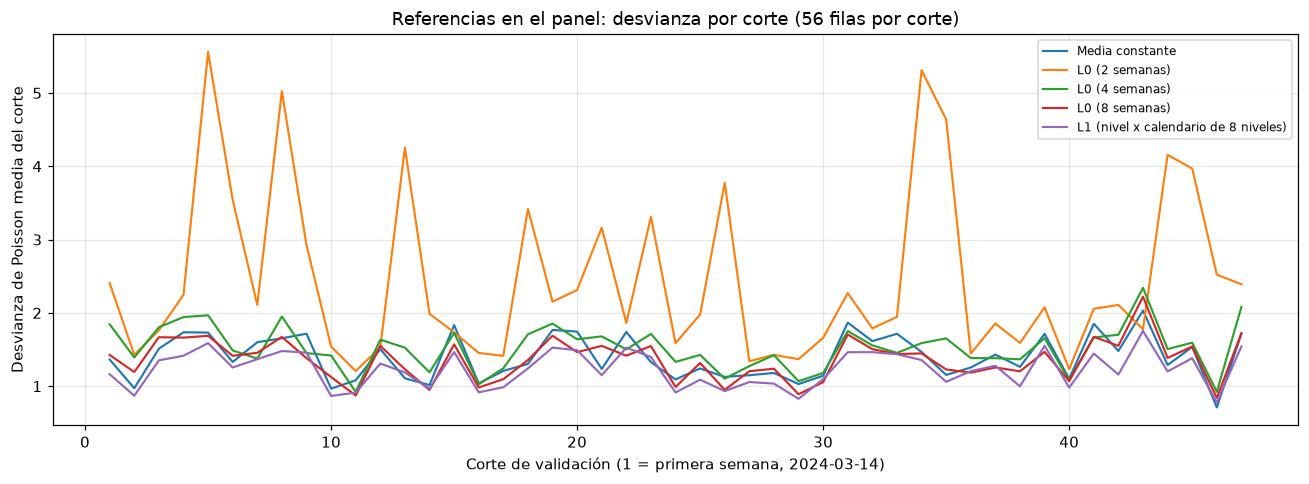

  guardado: experiments\modelos_candidatos\figuras\fig2_referencias_por_municipio.png


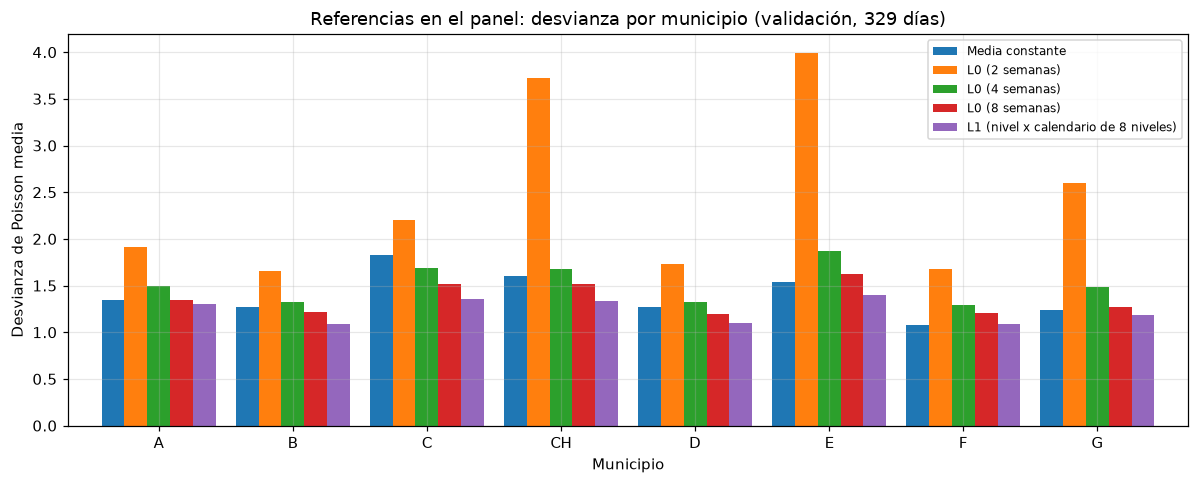

  guardado: experiments\modelos_candidatos\figuras\fig3_total_semanal_referencias.png


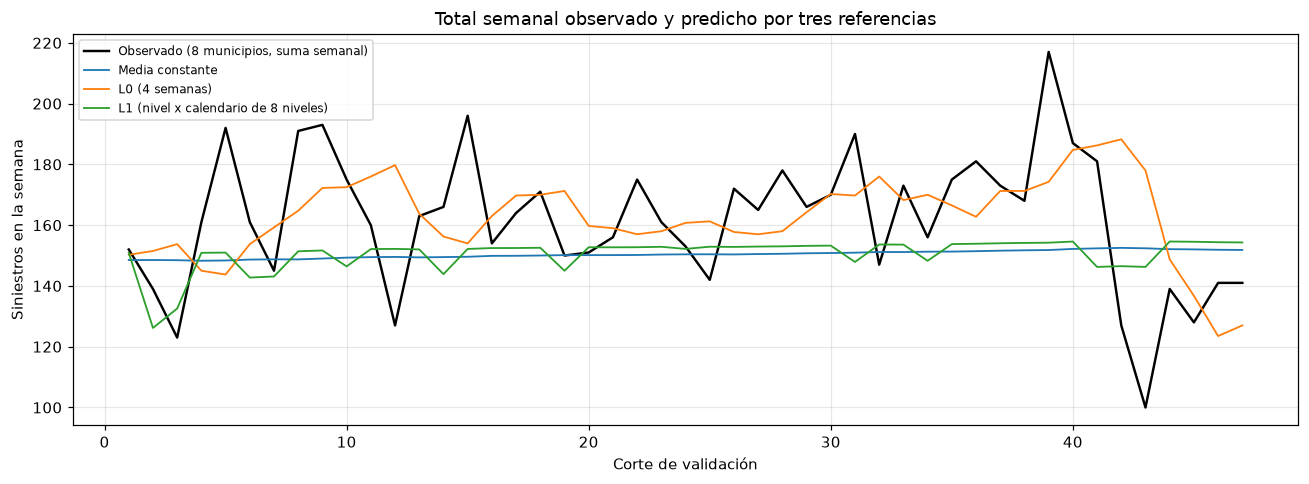

In [10]:
# fig1: desvianza por corte de cada referencia
fig, ax = plt.subplots(figsize=(12, 4.5))
for nombre in pred_ref:
    d = por_corte[por_corte["modelo"] == nombre]
    ax.plot(d["corte"], d["desvianza_poisson"], lw=1.4, label=nombre)
ax.set_xlabel("Corte de validación (1 = primera semana, 2024-03-14)")
ax.set_ylabel("Desvianza de Poisson media del corte")
ax.set_title("Referencias en el panel: desvianza por corte (56 filas por corte)")
ax.legend(fontsize=8)
fig.tight_layout()
guardar_figura(fig, "fig1_referencias_por_corte.png")
plt.show()

# fig2: desvianza por municipio
piv = por_mun.pivot(index="zona_id", columns="modelo", values="desvianza_poisson")
piv.index = [i.replace("MUNICIPIO ", "") for i in piv.index]
fig, ax = plt.subplots(figsize=(11, 4.5))
piv[list(pred_ref)].plot.bar(ax=ax, width=0.85)
ax.set_xlabel("Municipio")
ax.set_ylabel("Desvianza de Poisson media")
ax.set_title("Referencias en el panel: desvianza por municipio (validación, 329 días)")
ax.legend(fontsize=8)
plt.setp(ax.get_xticklabels(), rotation=0)
fig.tight_layout()
guardar_figura(fig, "fig2_referencias_por_municipio.png")
plt.show()

# fig3: total semanal observado vs L1 y media constante
sem = todas.assign(fecha=pd.to_datetime(todas["fecha"])).groupby(["modelo", "corte"]).agg(
    obs=("n_siniestros", "sum"), pred=("pred", "sum")).reset_index()
fig, ax = plt.subplots(figsize=(12, 4.5))
o = sem[sem["modelo"] == "Media constante"]
ax.plot(o["corte"], o["obs"], "k-", lw=1.6, label="Observado (8 municipios, suma semanal)")
for nombre in ("Media constante", "L0 (4 semanas)", "L1 (nivel x calendario de 8 niveles)"):
    d = sem[sem["modelo"] == nombre]
    ax.plot(d["corte"], d["pred"], lw=1.2, label=nombre)
ax.set_xlabel("Corte de validación")
ax.set_ylabel("Siniestros en la semana")
ax.set_title("Total semanal observado y predicho por tres referencias")
ax.legend(fontsize=8)
fig.tight_layout()
guardar_figura(fig, "fig3_total_semanal_referencias.png")
plt.show()

## 7. Paso A — conjuntos de variables (ventana expansiva)

Reglas aplicadas: sección 1, adenda (ítems 2, 3 y 4) y precisiones de la fase 2 (D31 a D34 e ítem 5).

- **Familias.** GLM Poisson (`statsmodels`, enlace log, IRLS con los valores por defecto) y XGBoost con
  `objective="count:poisson"`, `max_depth=3`, `n_estimators=300`, `learning_rate=0.05` (D19) y el resto
  fijo (ítem 5 de las precisiones).
- **Conjuntos** (0), (a), (b) y (c); N ∈ {28, 56, 91} en (0) y en (c), elegido por desvianza media en
  validación **por separado en cada familia** (adenda, ítem 2).
- **Variables** sólo desde `src/variables.py` (`matriz_entrenamiento` para el entrenamiento con origen
  simulado, `variables_horizonte` para los 7 días a predecir), con la matriz de D31 y la forma de D34.
  Las mismas filas de entrenamiento para todos los conjuntos (decisión 2 de la Etapa 1).
- **Registro.** Cada configuración agrega una fila a `experiments/modelos_candidatos/registro_experimentos.csv`
  (D33: se reescribe en cada ejecución). Predicciones por corte, día y municipio en `tablas/17`.
- **Avisos y convergencia** de cada ajuste, por corte, en `tablas/16`. No se silencian: se registran.
- **Elección del conjunto por familia** con el ítem 4 de la adenda y D32. Se compara contra **L1** y
  **L0 de 8 semanas** (adenda, ítem 1), con el mismo motor y los mismos 47 cortes.

In [11]:
import json
from datetime import datetime
import statsmodels.api as sm
from statsmodels.discrete.discrete_model import NegativeBinomial

# --- Matriz de diseño (D31, D34): la misma para GLM y XGBoost ---
MUNICIPIOS = sorted(panel["zona_id"].unique())
MUN_COLS = ["mun_" + z.replace("MUNICIPIO ", "") for z in MUNICIPIOS]          # 8 columnas, sin constante
CAL_COLS = ["cal_" + n for n in var.NIVELES_CALENDARIO if n != "lunes"]        # 7 columnas, lunes = referencia
A_COLS = [c for c in var.COLUMNAS_A_X_CALENDARIO if c != "a_x_lunes"]          # 7 columnas, sin a_x_lunes
REZ_COLS = [f"rezago_{k}" for k in var.REZAGOS]                                # conteos crudos (D34)
SIMPLICIDAD = {"a": 1, "b": 2, "c": 3}                                         # adenda, ítem 4


def columnas_conjunto(conjunto, n=None):
    "Columnas de cada conjunto anidado de la sección 1; `n` = días del nivel reciente en (0) y (c)."
    if conjunto == "0":
        return MUN_COLS + [f"log_nivel_reciente_{n}"] + REZ_COLS
    cols = MUN_COLS + CAL_COLS
    if conjunto in ("b", "c"):
        cols = cols + A_COLS
    if conjunto == "c":
        cols = cols + [f"log_nivel_reciente_{n}"]
    return cols


NIVELES_VERIFICADOS = []      # cantidad de valores de nivel reciente comprobados > 0 (D34)


def disenio(df):
    "Matriz a partir de la salida de var.matriz_entrenamiento o var.variables_horizonte (sin calcular variables nuevas)."
    X = df[["fecha", "zona_id"] + (["n_siniestros"] if "n_siniestros" in df else [])].copy()
    for z, c in zip(MUNICIPIOS, MUN_COLS):
        X[c] = (df["zona_id"] == z).astype(float)
    cal = df["calendario"].astype(str)
    for c in CAL_COLS:
        X[c] = (cal == c.removeprefix("cal_")).astype(float)
    for c in A_COLS:
        X[c] = df[c].astype(float)
    for n in var.NIVELES_RECIENTES:
        nivel = df[f"nivel_reciente_{n}"]
        assert (nivel > 0).all(), f"nivel_reciente_{n} vale 0 (o falta) en alguna fila: log no definido (D34)"
        NIVELES_VERIFICADOS.append(len(nivel))
        X[f"log_nivel_reciente_{n}"] = np.log(nivel)
    for c in REZ_COLS:
        X[c] = df[c].astype(float)
    return X


_MATRICES = {}


def matrices(vista, origen, ventana):
    "Matrices de entrenamiento y del horizonte del corte; se calculan una vez por (origen, ventana) y se reusan."
    assert vista["zona_id"].nunique() == 8, "los candidatos se evalúan sólo sobre el panel completo"
    clave = (origen, ventana)
    if clave not in _MATRICES:
        ent = var.matriz_entrenamiento(vista, origen, dias_ventana=ventana)
        hor = var.variables_horizonte(vista, origen, dias_ventana=ventana)
        assert ent["fecha"].max() < origen and hor["fecha"].min() == origen and len(hor) == 56
        _MATRICES[clave] = (disenio(ent), disenio(hor))
    return _MATRICES[clave]


# --- Ajuste de cada familia (GLM Poisson y XGBoost desde el paso A; NB2 en el paso B) ---
XGB_FIJOS = dict(objective="count:poisson", tree_method="hist", subsample=1, colsample_bytree=1,
                 min_child_weight=1, reg_lambda=1, random_state=SEMILLA, n_jobs=1)    # ítem 5 de las precisiones
XGB_PASO_A = dict(max_depth=3, n_estimators=300, learning_rate=0.05)                 # D19

AJUSTES = []      # una fila por (configuración, corte): filas, convergencia, avisos, dispersión de Pearson


def con_avisos(f):
    "Ejecuta f() y devuelve también los avisos emitidos. No silencia nada (salvo el DeprecationWarning de pandas ya filtrado)."
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")
        warnings.filterwarnings("ignore", message="The .generic. unit for NumPy timedelta", category=DeprecationWarning)
        out = f()
    return out, [f"{a.category.__name__}: {a.message}" for a in avisos]


def ajustar_nb2(X, y, Xh):
    "NB2 con α por máxima verosimilitud en el corte (adenda, ítem 5); si no converge según el ítem 6 (D29), plan B (D28)."
    res, avisos = con_avisos(lambda: NegativeBinomial(y, X, loglike_method="nb2").fit(method="newton", maxiter=100, disp=0))
    alpha = float(res.params["alpha"])
    no_convergio = (not res.mle_retvals["converged"]
                    or any(a.startswith("ConvergenceWarning") for a in avisos)
                    or not np.isfinite(alpha) or alpha <= 0)
    extra = {"convergio": not no_convergio, "iteraciones": res.mle_retvals["iterations"], "alpha_mv": alpha,
             "plan_b": no_convergio, "alpha_momentos": np.nan}
    if not no_convergio:
        return res.predict(Xh), extra, avisos
    # Plan B (D28): GLM NB con α por momentos en el mismo corte. Regresión auxiliar sin intercepto de ((y − μ)² − y)/μ
    # sobre μ, con μ del GLM Poisson ajustado en el entrenamiento de este corte (Cameron y Trivedi, 1990).
    mu = sm.GLM(y, X, family=sm.families.Poisson()).fit().fittedvalues
    alpha_m = float(sm.OLS(((y - mu) ** 2 - y) / mu, mu).fit().params.iloc[0])
    assert np.isfinite(alpha_m) and alpha_m > 0, "α por momentos no positivo: caso no cubierto por D28; detenerse y consultar"
    res_b, avisos_b = con_avisos(lambda: sm.GLM(y, X, family=sm.families.NegativeBinomial(alpha=alpha_m)).fit())
    extra["alpha_momentos"] = alpha_m
    return res_b.predict(Xh), extra, avisos + avisos_b


def modelo_candidato(config, familia, conjunto, n=None, hiper=None):
    cols = columnas_conjunto(conjunto, n)

    def modelo(vista, origen, ventana):
        ent, hor = matrices(vista, origen, ventana)
        X, y, Xh = ent[cols], ent["n_siniestros"], hor[cols]
        fila = {"configuracion": config, "origen": origen, "filas_entrenamiento": len(ent),
                "dias_entrenamiento": ent["fecha"].nunique()}
        if familia == "GLM Poisson":
            res, avisos = con_avisos(lambda: sm.GLM(y, X, family=sm.families.Poisson()).fit())
            pred = res.predict(Xh)
            fila.update(convergio=bool(res.converged), iteraciones=res.fit_history["iteration"],
                        dispersion_pearson=res.pearson_chi2 / res.df_resid)
        elif familia == "XGBoost":
            m, avisos = con_avisos(lambda: xgboost.XGBRegressor(**XGB_FIJOS, **hiper).fit(X, y))
            pred = m.predict(Xh)
        elif familia == "NB2":
            pred, extra, avisos = ajustar_nb2(X, y, Xh)
            fila.update(extra)
        else:
            raise ValueError(familia)
        fila.update(n_avisos=len(avisos), avisos=" | ".join(sorted(set(avisos))))
        AJUSTES.append(fila)
        return hor[["fecha", "zona_id"]].assign(pred=np.asarray(pred, dtype=float))
    return modelo


# --- Evaluación y registro (D33) ---
REGISTRO, PRED_CAND, META = [], {}, {}
RUTA_REGISTRO = DIR_EXPERIMENTO / "registro_experimentos.csv"


def evaluar_configuracion(paso, config, familia, conjunto, n=None, hiper=None, ventana=None):
    "Backtest de una configuración en los 47 cortes y su fila del registro."
    pred = backtest(panel, modelo_candidato(config, familia, conjunto, n, hiper), ventana=ventana)
    PRED_CAND[config] = pred
    hip = {"GLM Poisson": lambda: {"familia": "Poisson", "enlace": "log", "ajuste": "IRLS (statsmodels GLM, por defecto)"},
           "NB2": lambda: {"familia": "binomial negativa NB2 (varianza μ + αμ²)", "enlace": "log",
                           "ajuste": "NegativeBinomial(loglike_method='nb2').fit(method='newton', maxiter=100)",
                           "alpha": "máxima verosimilitud en cada corte", "plan_b": "GLM NB con α por momentos (D28)"},
           "XGBoost": lambda: {**XGB_FIJOS, **hiper}}[familia]()
    META[config] = dict(paso=paso, modelo=familia, conjunto=conjunto, N=n, ventana=ventana, hiper=hiper)
    g = evaluar(pred["n_siniestros"], pred["pred"])
    est = resumen_estabilidad({config: pred}).iloc[0]
    aj = pd.DataFrame([a for a in AJUSTES if a["configuracion"] == config])
    assert len(aj) == len(ORIGENES)
    no_conv = int((~aj["convergio"].astype(bool)).sum()) if "convergio" in aj and aj["convergio"].notna().all() else None
    REGISTRO.append({
        "paso": paso, "configuracion": config, "modelo": familia, "conjunto": conjunto, "N": n,
        "hiperparametros": json.dumps(hip, ensure_ascii=False),
        "ventana": "expansiva" if ventana is None else f"deslizante {ventana} días",
        "n_predicciones": g["n"], "desvianza": est["desvianza_media"],
        "error_estandar": est["error_estandar_47_cortes"], "mae": g["mae"], "rmse": g["rmse"],
        "total_pred_obs": g["razon_total"], "dias_prediccion_cero": g["dias_prediccion_cero"],
        "peor_municipio": est["peor_municipio"], "desvianza_peor_municipio": est["desvianza_peor_municipio"],
        "desvio_entre_cortes": est["desvio_entre_cortes"],
        "cortes_no_convergidos": no_conv, "cortes_con_avisos": int((aj["n_avisos"] > 0).sum()),
        "cortes_plan_b": int(aj["plan_b"].sum()) if "plan_b" in aj else None,     # sólo aplica a NB2
        "fecha_hora": datetime.now().isoformat(timespec="seconds"),
    })
    assert abs(g["desvianza_poisson"] - est["desvianza_media"]) < 1e-9     # cortes de igual peso (sección 4)
    return pred


def escribir_registro():
    reg = pd.DataFrame(REGISTRO)
    reg.round(6).to_csv(RUTA_REGISTRO, index=False, encoding="utf-8")
    print("  guardado:", RUTA_REGISTRO.relative_to(RAIZ), f"({len(reg)} filas)")
    return reg

In [12]:
CONFIGS_A = []
for familia, hiper in (("GLM Poisson", None), ("XGBoost", XGB_PASO_A)):
    for conjunto in ("0", "a", "b", "c"):
        for n in (var.NIVELES_RECIENTES if conjunto in ("0", "c") else (None,)):
            config = f"{familia} ({conjunto})" + (f" N={n}" if n else "")
            evaluar_configuracion("A", config, familia, conjunto, n, hiper)
            CONFIGS_A.append(config)

print(f"nivel reciente > 0 en todos los valores usados (D34): {sum(NIVELES_VERIFICADOS):,} comprobados")
ajustes_a = pd.DataFrame([a for a in AJUSTES if a["configuracion"] in CONFIGS_A])
ajustes_a["origen"] = ajustes_a["origen"].dt.strftime("%Y-%m-%d")
guardar_tabla(ajustes_a.round(6), "16_paso_a_ajustes_por_corte.csv")
print("ajustes con avisos:", int((ajustes_a["n_avisos"] > 0).sum()), "de", len(ajustes_a),
      "| GLM no convergidos:", int((ajustes_a["convergio"] == False).sum()))
registro = escribir_registro()
registro[["configuracion", "desvianza", "error_estandar", "total_pred_obs", "peor_municipio",
          "cortes_no_convergidos", "cortes_con_avisos"]].round(4)

nivel reciente > 0 en todos los valores usados (D34): 1,200,192 comprobados
  guardado: experiments\modelos_candidatos\tablas\16_paso_a_ajustes_por_corte.csv (752 filas)
ajustes con avisos: 0 de 752 | GLM no convergidos: 0
  guardado: experiments\modelos_candidatos\registro_experimentos.csv (16 filas)


,configuracion,desvianza,error_estandar,total_pred_obs,peor_municipio,cortes_no_convergidos,cortes_con_avisos
0,GLM Poisson (0) N=28,1.2760,0.0389,0.9524,MUNICIPIO E,0.0,0
1,GLM Poisson (0) N=56,1.2769,0.0388,0.9485,MUNICIPIO E,0.0,0
2,GLM Poisson (0) N=91,1.2757,0.0389,0.9529,MUNICIPIO E,0.0,0
3,GLM Poisson (a),1.2302,0.0359,0.9341,MUNICIPIO E,0.0,0
4,GLM Poisson (b),1.2207,0.0362,0.9341,MUNICIPIO E,0.0,0
5,GLM Poisson (c) N=28,1.2150,0.0363,0.9523,MUNICIPIO E,0.0,0
6,GLM Poisson (c) N=56,1.2167,0.0363,0.9479,MUNICIPIO E,0.0,0
7,GLM Poisson (c) N=91,1.2168,0.0364,0.9480,MUNICIPIO E,0.0,0
8,XGBoost (0) N=28,1.2864,0.0395,0.9590,MUNICIPIO C,NaN,0
9,XGBoost (0) N=56,1.2866,0.0412,0.9675,MUNICIPIO C,NaN,0


In [13]:
REF_COMPARACION = {n: pred_ref[n] for n in ("L1 (nivel x calendario de 8 niveles)", "L0 (8 semanas)")}
L1 = "L1 (nivel x calendario de 8 niveles)"


def familia_de(nombre):
    return META[nombre]["modelo"] if nombre in META else "referencia"


def marcar_1ee(t, grupo=None, col="desvianza", ee="error_estandar"):
    "Marca las filas a menos de 1 error estándar de la mejor (la de menor desvianza), en toda la tabla o por grupo."
    def _m(g):
        mejor = g.loc[g[col].idxmin()]
        return g[col] <= mejor[col] + mejor[ee]
    if grupo is None:
        return _m(t)
    return t.groupby(grupo, group_keys=False).apply(_m, include_groups=False)


def tabla_comparacion(configs, referencias=REF_COMPARACION):
    "Tabla global: métricas, error estándar sobre 47 cortes, estabilidad y comparación contra L1 y L0 de 8 semanas."
    preds = {**{c: PRED_CAND[c] for c in configs}, **referencias}
    est = resumen_estabilidad(preds)
    t = tabla_metricas(preds).merge(est, on="modelo")
    t = t.rename(columns={"desvianza_media": "desvianza", "error_estandar_47_cortes": "error_estandar",
                          "razon_total": "total_pred_obs"}).drop(columns="desvianza_poisson")
    t.insert(1, "familia", t["modelo"].map(familia_de))
    pc = tabla_metricas(preds, "corte").pivot(index="corte", columns="modelo", values="desvianza_poisson")
    t["diferencia_vs_L1"] = t["desvianza"] - t.loc[t["modelo"] == L1, "desvianza"].iloc[0]
    t["diferencia_vs_L0_8sem"] = t["desvianza"] - t.loc[t["modelo"] == "L0 (8 semanas)", "desvianza"].iloc[0]
    t["cortes_que_gana_a_L1"] = t["modelo"].map(lambda m: int((pc[m] < pc[L1]).sum()))
    t["a_menos_de_1_ee_del_mejor_de_la_tabla"] = marcar_1ee(t)
    t["a_menos_de_1_ee_del_mejor_de_su_familia"] = marcar_1ee(t, "familia")
    return t.sort_values("desvianza").reset_index(drop=True)


def tabla_por_municipio(configs, referencias=REF_COMPARACION):
    "Por municipio: desvianza, su error estándar sobre los 47 cortes (7 filas por corte), total pred./obs. y marca de 1 EE."
    preds = {**{c: PRED_CAND[c] for c in configs}, **referencias}
    filas = []
    for nombre, df in preds.items():
        for z, g in df.groupby("zona_id"):
            d = np.array([evaluar(h["n_siniestros"], h["pred"])["desvianza_poisson"] for _, h in g.groupby("corte")])
            m = evaluar(g["n_siniestros"], g["pred"])
            filas.append({"zona_id": z, "modelo": nombre, "familia": familia_de(nombre),
                          "desvianza": m["desvianza_poisson"], "error_estandar": d.std(ddof=1) / np.sqrt(len(d)),
                          "mae": m["mae"], "total_pred_obs": m["razon_total"],
                          "dias_prediccion_cero": m["dias_prediccion_cero"]})
    t = pd.DataFrame(filas)
    t["a_menos_de_1_ee_del_mejor_del_municipio"] = marcar_1ee(t, "zona_id")
    return t.sort_values(["zona_id", "desvianza"]).reset_index(drop=True)


glob_a = tabla_comparacion(CONFIGS_A)
guardar_tabla(glob_a.round(6), "11_paso_a_globales.csv")
mun_a = tabla_por_municipio(CONFIGS_A)
guardar_tabla(mun_a.round(6), "12_paso_a_por_municipio.csv")

preds_a = {**{c: PRED_CAND[c] for c in CONFIGS_A}, **REF_COMPARACION}
corte_a = tabla_metricas(preds_a, "corte")
guardar_tabla(corte_a.round(6), "13_paso_a_por_corte.csv")

glob_a[["modelo", "desvianza", "error_estandar", "mae", "rmse", "total_pred_obs", "dias_prediccion_cero",
        "peor_municipio", "desvianza_peor_municipio", "diferencia_vs_L1", "cortes_que_gana_a_L1",
        "a_menos_de_1_ee_del_mejor_de_la_tabla", "a_menos_de_1_ee_del_mejor_de_su_familia"]].round(4)

  guardado: experiments\modelos_candidatos\tablas\11_paso_a_globales.csv (18 filas)


  guardado: experiments\modelos_candidatos\tablas\12_paso_a_por_municipio.csv (144 filas)


  guardado: experiments\modelos_candidatos\tablas\13_paso_a_por_corte.csv (846 filas)


,modelo,desvianza,error_estandar,mae,rmse,total_pred_obs,dias_prediccion_cero,peor_municipio,desvianza_peor_municipio,diferencia_vs_L1,cortes_que_gana_a_L1,a_menos_de_1_ee_del_mejor_de_la_tabla,a_menos_de_1_ee_del_mejor_de_su_familia
0,GLM Poisson (c) N=28,1.2150,0.0363,1.3981,1.7826,0.9523,0,MUNICIPIO E,1.4121,-0.0169,38,True,True
1,GLM Poisson (c) N=56,1.2167,0.0363,1.3992,1.7840,0.9479,0,MUNICIPIO E,1.4018,-0.0152,37,True,True
2,GLM Poisson (c) N=91,1.2168,0.0364,1.3996,1.7841,0.9480,0,MUNICIPIO E,1.4011,-0.0151,35,True,True
3,XGBoost (b),1.2200,0.0362,1.3997,1.7888,0.9338,0,MUNICIPIO E,1.3997,-0.0119,32,True,True
4,GLM Poisson (b),1.2207,0.0362,1.3990,1.7876,0.9341,0,MUNICIPIO E,1.3995,-0.0111,35,True,True
5,XGBoost (a),1.2217,0.0361,1.3999,1.7900,0.9338,0,MUNICIPIO E,1.4004,-0.0102,31,True,True
6,XGBoost (c) N=28,1.2219,0.0370,1.4051,1.7894,0.9586,0,MUNICIPIO E,1.4454,-0.0100,29,True,True
7,XGBoost (c) N=56,1.2224,0.0382,1.4082,1.7893,0.9667,0,MUNICIPIO E,1.4165,-0.0095,29,True,True
8,XGBoost (c) N=91,1.2243,0.0373,1.4074,1.7919,0.9730,0,MUNICIPIO E,1.4219,-0.0075,27,True,True
9,GLM Poisson (a),1.2302,0.0359,1.4013,1.7951,0.9341,0,MUNICIPIO E,1.4019,-0.0017,36,True,True


In [14]:
# Desvianza y total pred./obs. por municipio (pivote de tablas/12); * = a menos de 1 EE del mejor del municipio
_p = mun_a.assign(v=mun_a["desvianza"].map("{:.4f}".format)
                  + np.where(mun_a["a_menos_de_1_ee_del_mejor_del_municipio"], "*", ""))
print("Desvianza por municipio (* = a menos de 1 EE del mejor del municipio)")
display(_p.pivot(index="modelo", columns="zona_id", values="v").loc[glob_a["modelo"]])
print("Total predicho / observado por municipio")
mun_a.pivot(index="modelo", columns="zona_id", values="total_pred_obs").loc[glob_a["modelo"]].round(4)

Desvianza por municipio (* = a menos de 1 EE del mejor del municipio)


zona_id,MUNICIPIO A,MUNICIPIO B,MUNICIPIO C,MUNICIPIO CH,MUNICIPIO D,MUNICIPIO E,MUNICIPIO F,MUNICIPIO G
modelo,,,,,,,,
GLM Poisson (c) N=28,1.2165*,1.0870*,1.3363*,1.3277*,1.0958*,1.4121*,1.0647*,1.1796*
GLM Poisson (c) N=56,1.2209*,1.0827*,1.3397*,1.3343*,1.0982*,1.4018*,1.0743*,1.1814*
GLM Poisson (c) N=91,1.2225*,1.0848*,1.3368*,1.3322*,1.1015*,1.4011*,1.0736*,1.1815*
XGBoost (b),1.2478*,1.0833*,1.3459*,1.3408*,1.1044*,1.3997*,1.0594*,1.1785*
GLM Poisson (b),1.2388*,1.0836*,1.3484*,1.3307*,1.0991*,1.3995*,1.0818*,1.1840*
XGBoost (a),1.2511*,1.0826*,1.3449*,1.3410*,1.1068*,1.4004*,1.0658*,1.1806*
XGBoost (c) N=28,1.2285*,1.0903*,1.3573*,1.3318*,1.1021*,1.4454*,1.0511*,1.1685*
XGBoost (c) N=56,1.2174*,1.0829*,1.3614*,1.3496*,1.1076*,1.4165*,1.0674*,1.1766*
XGBoost (c) N=91,1.2130*,1.0886*,1.3699*,1.3335*,1.1110*,1.4219*,1.0741*,1.1826*


Total predicho / observado por municipio


zona_id,MUNICIPIO A,MUNICIPIO B,MUNICIPIO C,MUNICIPIO CH,MUNICIPIO D,MUNICIPIO E,MUNICIPIO F,MUNICIPIO G
modelo,,,,,,,,
GLM Poisson (c) N=28,0.9001,1.0058,0.9378,1.0117,0.9685,0.9483,0.9160,0.9529
GLM Poisson (c) N=56,0.8917,1.0083,0.9315,1.0143,0.9653,0.9440,0.9083,0.9440
GLM Poisson (c) N=91,0.8927,1.0092,0.9319,1.0134,0.9640,0.9433,0.9091,0.9439
XGBoost (b),0.8613,0.9897,0.9036,1.0221,0.9459,0.9490,0.9015,0.9422
GLM Poisson (b),0.8692,1.0018,0.9138,1.0050,0.9590,0.9328,0.8897,0.9277
XGBoost (a),0.8631,0.9934,0.9059,1.0180,0.9487,0.9450,0.8978,0.9387
XGBoost (c) N=28,0.9115,0.9873,0.9163,1.0332,0.9502,0.9820,0.9616,0.9754
XGBoost (c) N=56,0.9142,1.0017,0.9310,1.0408,0.9457,0.9574,0.9930,0.9922
XGBoost (c) N=91,0.9492,1.0067,0.9455,1.0296,0.9480,0.9594,0.9737,1.0024


In [15]:
def elegir_conjunto(familia, glob, configs):
    "Ítem 4 de la adenda con D32. Devuelve (configuración elegida, filas con cada paso de la regla)."
    g = glob.set_index("modelo")
    dev, ee = g["desvianza"], g["error_estandar"]
    propias = [c for c in configs if META[c]["modelo"] == familia]
    pasos, mejor_n = [], {}
    for conj in ("0", "c"):                                           # adenda, ítem 2: N por desvianza media
        cands = [c for c in propias if META[c]["conjunto"] == conj]
        mejor_n[conj] = min(cands, key=lambda c: dev[c])
        for c in cands:
            pasos.append({"familia": familia, "paso": f"N de ({conj}) por desvianza media", "configuracion": c,
                          "desvianza": dev[c], "error_estandar": ee[c], "resultado": "elegido" if c == mejor_n[conj] else ""})
    abc = [c for c in propias if META[c]["conjunto"] in ("a", "b")] + [mejor_n["c"]]
    mejor = min(abc, key=lambda c: dev[c])
    umbral = dev[mejor] + ee[mejor]
    empatados = [c for c in abc if dev[c] <= umbral]
    elegido = min(empatados, key=lambda c: SIMPLICIDAD[META[c]["conjunto"]])
    for c in abc:
        pasos.append({"familia": familia, "paso": "(a), (b), (c): a menos de 1 EE del mejor", "configuracion": c,
                      "desvianza": dev[c], "error_estandar": ee[c],
                      "resultado": ("mejor; " if c == mejor else "") + (f"empatado (≤ {umbral:.4f})" if c in empatados else f"fuera (> {umbral:.4f})")})
    pasos.append({"familia": familia, "paso": "el más simple entre los empatados (a < b < c)", "configuracion": elegido,
                  "desvianza": dev[elegido], "error_estandar": ee[elegido], "resultado": "elegido entre (a), (b), (c)"})
    cero = mejor_n["0"]
    mejora = dev[elegido] - dev[cero]
    reemplaza = bool(mejora > ee[cero])                                # D32
    pasos.append({"familia": familia, "paso": "¿(0) reemplaza? desv(elegido) − desv(0) > EE(0)", "configuracion": cero,
                  "desvianza": dev[cero], "error_estandar": ee[cero],
                  "resultado": f"{mejora:.4f} {'>' if reemplaza else '≤'} {ee[cero]:.4f}: {'reemplaza' if reemplaza else 'no reemplaza'}"})
    final = cero if reemplaza else elegido
    pasos.append({"familia": familia, "paso": "conjunto elegido para la familia", "configuracion": final,
                  "desvianza": dev[final], "error_estandar": ee[final], "resultado": "ELEGIDO"})
    return final, pasos


ELEGIDO_A, _filas = {}, []
for fam in ("GLM Poisson", "XGBoost"):
    ELEGIDO_A[fam], p = elegir_conjunto(fam, glob_a, CONFIGS_A)
    _filas += p
eleccion_a = pd.DataFrame(_filas)
guardar_tabla(eleccion_a.round(6), "14_paso_a_eleccion.csv")
print("Elegido por familia:", ELEGIDO_A)
eleccion_a.round(4)

  guardado: experiments\modelos_candidatos\tablas\14_paso_a_eleccion.csv (24 filas)
Elegido por familia: {'GLM Poisson': 'GLM Poisson (a)', 'XGBoost': 'XGBoost (a)'}


,familia,paso,configuracion,desvianza,error_estandar,resultado
0,GLM Poisson,N de (0) por desvianza media,GLM Poisson (0) N=28,1.2760,0.0389,
1,GLM Poisson,N de (0) por desvianza media,GLM Poisson (0) N=56,1.2769,0.0388,
2,GLM Poisson,N de (0) por desvianza media,GLM Poisson (0) N=91,1.2757,0.0389,elegido
3,GLM Poisson,N de (c) por desvianza media,GLM Poisson (c) N=28,1.2150,0.0363,elegido
4,GLM Poisson,N de (c) por desvianza media,GLM Poisson (c) N=56,1.2167,0.0363,
5,GLM Poisson,N de (c) por desvianza media,GLM Poisson (c) N=91,1.2168,0.0364,
6,GLM Poisson,"(a), (b), (c): a menos de 1 EE del mejor",GLM Poisson (a),1.2302,0.0359,empatado (≤ 1.2513)
7,GLM Poisson,"(a), (b), (c): a menos de 1 EE del mejor",GLM Poisson (b),1.2207,0.0362,empatado (≤ 1.2513)
8,GLM Poisson,"(a), (b), (c): a menos de 1 EE del mejor",GLM Poisson (c) N=28,1.2150,0.0363,mejor; empatado (≤ 1.2513)
9,GLM Poisson,el más simple entre los empatados (a < b < c),GLM Poisson (a),1.2302,0.0359,"elegido entre (a), (b), (c)"


In [16]:
# Dispersión de Pearson del GLM Poisson con el conjunto elegido: chi² de Pearson / gl residuales, en el entrenamiento de cada corte
_disp = ajustes_a[ajustes_a["configuracion"] == ELEGIDO_A["GLM Poisson"]][["origen", "filas_entrenamiento", "dispersion_pearson"]]
_disp = _disp.reset_index(drop=True)
_disp.insert(0, "corte", range(1, len(_disp) + 1))
dispersion = pd.DataFrame([{
    "configuracion": ELEGIDO_A["GLM Poisson"], "n_cortes": len(_disp),
    "minimo": _disp["dispersion_pearson"].min(), "mediana": _disp["dispersion_pearson"].median(),
    "maximo": _disp["dispersion_pearson"].max(),
    "primer_corte": _disp["dispersion_pearson"].iloc[0], "ultimo_corte": _disp["dispersion_pearson"].iloc[-1],
}])
guardar_tabla(dispersion.round(6), "15_paso_a_dispersion_pearson.csv")
dispersion.round(4)

  guardado: experiments\modelos_candidatos\tablas\15_paso_a_dispersion_pearson.csv (1 filas)


,configuracion,n_cortes,minimo,mediana,maximo,primer_corte,ultimo_corte
0,GLM Poisson (a),47,1.1035,1.1109,1.1171,1.11,1.1124


  guardado: experiments\modelos_candidatos\figuras\fig4_paso_a_desvianza.png


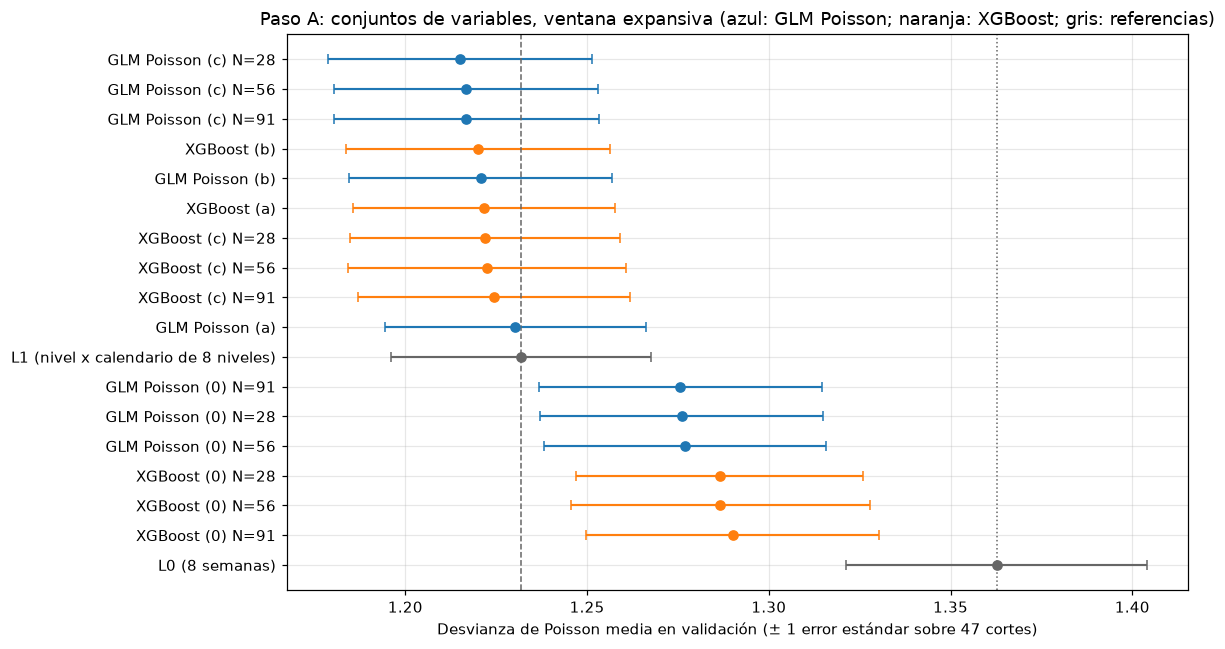

  guardado: experiments\modelos_candidatos\tablas\17_paso_a_predicciones.csv (42112 filas)


,configuracion,corte,origen,fecha,zona_id,n_siniestros,pred
0,GLM Poisson (0) N=28,1,2024-03-14,2024-03-14,MUNICIPIO A,0,2.753226
1,GLM Poisson (0) N=28,1,2024-03-14,2024-03-14,MUNICIPIO B,3,3.511780
2,GLM Poisson (0) N=28,1,2024-03-14,2024-03-14,MUNICIPIO C,4,3.251888
3,GLM Poisson (0) N=28,1,2024-03-14,2024-03-14,MUNICIPIO CH,1,2.098869
4,GLM Poisson (0) N=28,1,2024-03-14,2024-03-14,MUNICIPIO D,3,3.133004
...,...,...,...,...,...,...,...
42107,XGBoost (c) N=91,47,2025-01-30,2025-02-05,MUNICIPIO CH,3,2.266686
42108,XGBoost (c) N=91,47,2025-01-30,2025-02-05,MUNICIPIO D,6,3.361124
42109,XGBoost (c) N=91,47,2025-01-30,2025-02-05,MUNICIPIO E,6,2.308086
42110,XGBoost (c) N=91,47,2025-01-30,2025-02-05,MUNICIPIO F,3,3.098880


In [17]:
# fig4: desvianza ± 1 EE de las configuraciones del paso A, con L1 y L0 de 8 semanas
fig, ax = plt.subplots(figsize=(11, 6))
t = glob_a.iloc[::-1]
y_pos = pd.Series(range(len(t)), index=t.index)
for fam, color in (("GLM Poisson", "C0"), ("XGBoost", "C1"), ("referencia", "0.4")):
    f = t[t["familia"] == fam]
    ax.errorbar(f["desvianza"], y_pos[f.index], xerr=f["error_estandar"], fmt="o", color=color, elinewidth=1.4, capsize=3)
ax.set_yticks(range(len(t)), t["modelo"])
for nombre, ls in ((L1, "--"), ("L0 (8 semanas)", ":")):
    ax.axvline(t.loc[t["modelo"] == nombre, "desvianza"].iloc[0], color="0.4", ls=ls, lw=1)
ax.set_xlabel("Desvianza de Poisson media en validación (± 1 error estándar sobre 47 cortes)")
ax.set_title("Paso A: conjuntos de variables, ventana expansiva (azul: GLM Poisson; naranja: XGBoost; gris: referencias)")
fig.tight_layout()
guardar_figura(fig, "fig4_paso_a_desvianza.png")
plt.show()

predicciones_a = pd.concat([PRED_CAND[c].assign(configuracion=c) for c in CONFIGS_A], ignore_index=True)
predicciones_a["origen"] = predicciones_a["origen"].dt.strftime("%Y-%m-%d")
predicciones_a["fecha"] = predicciones_a["fecha"].dt.strftime("%Y-%m-%d")
guardar_tabla(predicciones_a[["configuracion", "corte", "origen", "fecha", "zona_id", "n_siniestros", "pred"]].round(6),
              "17_paso_a_predicciones.csv")

### 7.1 Lectura del paso A

Todas las cifras salen de `tablas/11` (globales), `12` (por municipio), `13` (por corte), `14` (elección), `15`
(dispersión de Pearson) y `16` (ajustes por corte). Desvianza = desvianza de Poisson media en validación (47 cortes).

**Evidencia**

- **Elección por familia (ítem 4 de la adenda, D32).** En las dos familias, (a), (b) y (c) quedan a menos de 1 error
  estándar del mejor de los tres, y la simplicidad elige **(a)**:
  - GLM Poisson: el mejor es (c) N=28 (1,2150; EE 0,0363; umbral 1,2513); elegido **(a)** (1,2302; EE 0,0359).
  - XGBoost: el mejor es (b) (1,2200; EE 0,0362; umbral 1,2562); elegido **(a)** (1,2217; EE 0,0361).
  - (0) no reemplaza en ninguna: GLM (0) N=91 da 1,2757 (desv(a) − desv(0) = −0,0454 ≤ EE(0) = 0,0389); XGBoost (0)
    N=28 da 1,2864 (−0,0648 ≤ 0,0395). (0) es peor que (a), no mejor.
- **N elegido:** GLM (0) N=91, GLM (c) N=28, XGBoost (0) N=28, XGBoost (c) N=28. Entre los tres N de cada conjunto la
  desvianza cambia a lo sumo 0,0036, muy por debajo de 1 EE.
- **Contra las referencias.** L1 (1,2319; EE 0,0358) también queda a menos de 1 EE del mejor de la tabla: **por el
  criterio de 1 EE, ninguna configuración de (a), (b) o (c) se distingue de L1**. GLM (a) queda a −0,0017 de L1; la
  mejor configuración, GLM (c) N=28, a −0,0169, y le gana a L1 en 38 de 47 cortes. Las seis de (0) quedan por encima de
  L1 (+0,0438 a +0,0581) y por debajo de L0 de 8 semanas (−0,0726 a −0,0870).
- **Ajustes:** 752 (16 configuraciones × 47 cortes), **ningún aviso**; los 376 ajustes del GLM convergieron (5
  iteraciones de IRLS cada uno). Ninguna predicción igual a 0. El peor municipio es E en todas las configuraciones salvo
  las tres de XGBoost (0), donde es C.
- **Dispersión de Pearson del GLM Poisson (a)**, en el entrenamiento de cada corte: de 1,1035 a 1,1171, mediana 1,1109.

**¿(c) corrige la subestimación de L1 (total pred./obs. 0,9305)?** *Evidencia:* en parte. El total predicho / observado
pasa de 0,9341 en GLM (a) a 0,9523 en GLM (c) N=28 (0,9479 y 0,9480 con N=56 y 91), y de 0,9338 en XGBoost (a) a entre
0,9586 y 0,9730 en XGBoost (c). Ninguna llega a 1. Por municipio, A sigue siendo el más subestimado (GLM (c) N=28: 0,9001,
contra 0,8641 de L1), seguido de F (0,9160, contra 0,8862). En desvianza, GLM (c) N=28 mejora a GLM (a) en 0,0152 y le gana
en 38 de 47 cortes, pero queda dentro de 1 EE; en XGBoost, (c) N=28 no mejora a (a) (+0,0002; gana en 26 de 47).
*Inferencia:* el nivel reciente absorbe una parte de la tendencia creciente, pero no toda. Qué explica el resto no se
investigó en este paso.

**¿El término de A aporta en el panel como en el diagnóstico?** *Evidencia:* en el GLM, sí en A y casi nada en el global.
La desvianza de A baja de 1,2950 con (a) a 1,2388 con (b), un −4,34 %. En el diagnóstico, el calendario propio mejoraba a A
en 4,06 % y 4,24 % en los dos pliegues (`resumen_diagnostico_municipios.md` §7.3). Son protocolos distintos (allí, un ajuste
fijo por pliegue), así que se compara la dirección y el orden de magnitud, no la cifra. Globalmente, (b) mejora a (a) en
0,0095 (EE 0,0362) y le gana en 33 de 47 cortes. En XGBoost el término casi no cambia nada: A pasa de 1,2511 a 1,2478 y el
global, de 1,2217 a 1,2200. *Inferencia:* XGBoost (a) ya modela A mejor que GLM (a) (1,2511 contra 1,2950), lo que sugiere que
los árboles de profundidad 3 encuentran la interacción municipio × calendario sin el término explícito.

**Inferencia general.** Con este protocolo y esta regla, ninguno de los bloques que el diagnóstico motivó (término de A,
nivel reciente) supera el umbral de 1 EE. El EE se calcula entre cortes y recoge las semanas difíciles que afectan a todos
los modelos por igual; las comparaciones corte a corte (38 de 47, 33 de 47) muestran diferencias más consistentes de lo que el
umbral deja ver. La regla está fijada y se aplica como está; esta lectura no la modifica.

## 8. Paso B — hiperparámetros de XGBoost y binomial negativa (ventana expansiva)

Sobre el conjunto elegido en el paso A para cada familia (sección 7: **(a)** en las dos; el código lo toma de `ELEGIDO_A`).

- **XGBoost:** las 12 combinaciones de la grilla de la sección 1 (`max_depth` ∈ {2, 3, 4} × `n_estimators` ∈ {100, 300} ×
  `learning_rate` ∈ {0.05, 0.1}), con el resto de los parámetros fijos (ítem 5 de las precisiones de la fase 2). La combinación
  (3, 300, 0.05) es la del paso A: se vuelve a evaluar y se verifica que da exactamente las mismas predicciones.
- **Binomial negativa NB2** (adenda, ítems 5 y 6): α por máxima verosimilitud en cada corte, `method="newton"`, `maxiter=100`. Un
  corte es **no convergido** si `mle_retvals["converged"]` es `False`, si hay un `ConvergenceWarning` o si α no es finito o no es
  positivo; en ese corte se usa el **plan B** (D28). Se reporta α por corte y cuántos cortes usaron el plan B. Si el α por momentos
  del plan B no fuera positivo (caso que D28 no cubre), la ejecución se detiene.
- **Selección por familia** con la regla de la sección 1 y las precisiones D36 a D38: familia GLM = GLM Poisson (a) del paso A y
  NB2 (a); familia XGBoost = las 12 combinaciones. Cada paso de la regla queda en `tablas/23`.

In [18]:
GRILLA_XGB = [dict(max_depth=d, n_estimators=n, learning_rate=lr) for d in (2, 3, 4) for n in (100, 300) for lr in (0.05, 0.1)]
CONJ_GLM_B = META[ELEGIDO_A["GLM Poisson"]]["conjunto"]
CONJ_XGB_B = META[ELEGIDO_A["XGBoost"]]["conjunto"]


def nombre_xgb(conjunto, h):
    return f"XGBoost ({conjunto}) d={h['max_depth']} n={h['n_estimators']} lr={h['learning_rate']}"


CONFIG_NB2 = f"NB2 ({CONJ_GLM_B})"
evaluar_configuracion("B", CONFIG_NB2, "NB2", CONJ_GLM_B)
CONFIGS_B_XGB = []
for h in GRILLA_XGB:
    CONFIGS_B_XGB.append(nombre_xgb(CONJ_XGB_B, h))
    evaluar_configuracion("B", CONFIGS_B_XGB[-1], "XGBoost", CONJ_XGB_B, hiper=h)
CONFIGS_B_GLM = [ELEGIDO_A["GLM Poisson"], CONFIG_NB2]
CONFIGS_B = CONFIGS_B_GLM + CONFIGS_B_XGB

# Control: la combinación del paso A, evaluada de nuevo, da exactamente las mismas predicciones
_repetida = nombre_xgb(CONJ_XGB_B, XGB_PASO_A)
assert _repetida in CONFIGS_B_XGB
assert np.array_equal(PRED_CAND[_repetida]["pred"].to_numpy(), PRED_CAND[ELEGIDO_A["XGBoost"]]["pred"].to_numpy()), \
    "la combinación del paso A no reproduce sus predicciones"
print(f"control: {_repetida} reproduce exactamente las predicciones de {ELEGIDO_A['XGBoost']} (paso A)")

ajustes_b = pd.DataFrame([a for a in AJUSTES if a["configuracion"] in CONFIGS_B and META[a["configuracion"]]["paso"] == "B"])
ajustes_b["origen"] = ajustes_b["origen"].dt.strftime("%Y-%m-%d")
guardar_tabla(ajustes_b.round(6), "24_paso_b_ajustes_por_corte.csv")
print("ajustes con avisos:", int((ajustes_b["n_avisos"] > 0).sum()), "de", len(ajustes_b))
registro = escribir_registro()
registro.loc[registro["paso"] == "B", ["configuracion", "desvianza", "error_estandar", "total_pred_obs", "peor_municipio",
                                       "cortes_no_convergidos", "cortes_plan_b", "cortes_con_avisos"]].round(4)

control: XGBoost (a) d=3 n=300 lr=0.05 reproduce exactamente las predicciones de XGBoost (a) (paso A)
  guardado: experiments\modelos_candidatos\tablas\24_paso_b_ajustes_por_corte.csv (611 filas)
ajustes con avisos: 0 de 611
  guardado: experiments\modelos_candidatos\registro_experimentos.csv (29 filas)


,configuracion,desvianza,error_estandar,total_pred_obs,peor_municipio,cortes_no_convergidos,cortes_plan_b,cortes_con_avisos
16,NB2 (a),1.2301,0.0359,0.9341,MUNICIPIO E,0.0,0.0,0
17,XGBoost (a) d=2 n=100 lr=0.05,1.2671,0.0395,0.9332,MUNICIPIO C,NaN,NaN,0
18,XGBoost (a) d=2 n=100 lr=0.1,1.2375,0.0375,0.9336,MUNICIPIO E,NaN,NaN,0
19,XGBoost (a) d=2 n=300 lr=0.05,1.2276,0.0368,0.9337,MUNICIPIO E,NaN,NaN,0
20,XGBoost (a) d=2 n=300 lr=0.1,1.2202,0.0360,0.9339,MUNICIPIO E,NaN,NaN,0
21,XGBoost (a) d=3 n=100 lr=0.05,1.2443,0.0380,0.9335,MUNICIPIO C,NaN,NaN,0
22,XGBoost (a) d=3 n=100 lr=0.1,1.2264,0.0366,0.9337,MUNICIPIO E,NaN,NaN,0
23,XGBoost (a) d=3 n=300 lr=0.05,1.2217,0.0361,0.9338,MUNICIPIO E,NaN,NaN,0
24,XGBoost (a) d=3 n=300 lr=0.1,1.2211,0.0358,0.9339,MUNICIPIO E,NaN,NaN,0
25,XGBoost (a) d=4 n=100 lr=0.05,1.2290,0.0374,0.9336,MUNICIPIO E,NaN,NaN,0


In [19]:
# NB2: α por corte, convergencia y plan B
nb2 = ajustes_b[ajustes_b["configuracion"] == CONFIG_NB2][
    ["origen", "filas_entrenamiento", "convergio", "iteraciones", "alpha_mv", "plan_b", "alpha_momentos", "n_avisos", "avisos"]
].reset_index(drop=True)
nb2.insert(0, "corte", range(1, len(nb2) + 1))
guardar_tabla(nb2.round(6), "21_paso_b_nb2_por_corte.csv")

# NB2 contra GLM Poisson (mismo conjunto): desvianza, cortes ganados y diferencia entre predicciones
_p, _n = PRED_CAND[ELEGIDO_A["GLM Poisson"]], PRED_CAND[CONFIG_NB2]
assert _p[["corte", "fecha", "zona_id"]].equals(_n[["corte", "fecha", "zona_id"]])
_pc = tabla_metricas({"p": _p, "n": _n}, "corte").pivot(index="corte", columns="modelo", values="desvianza_poisson")
_est = resumen_estabilidad({"p": _p, "n": _n}).set_index("modelo")
nb2_vs_poisson = pd.DataFrame([{
    "glm_poisson": ELEGIDO_A["GLM Poisson"], "nb2": CONFIG_NB2,
    "desvianza_glm_poisson": _est.loc["p", "desvianza_media"], "desvianza_nb2": _est.loc["n", "desvianza_media"],
    "diferencia_nb2_menos_poisson": _est.loc["n", "desvianza_media"] - _est.loc["p", "desvianza_media"],
    "error_estandar_glm_poisson": _est.loc["p", "error_estandar_47_cortes"], "error_estandar_nb2": _est.loc["n", "error_estandar_47_cortes"],
    "cortes_que_gana_nb2": int((_pc["n"] < _pc["p"]).sum()),
    "max_dif_absoluta_predicciones": float(np.abs(_n["pred"] - _p["pred"]).max()),
    "max_dif_relativa_predicciones": float((np.abs(_n["pred"] - _p["pred"]) / _p["pred"]).max()),
    "cortes_plan_b": int(nb2["plan_b"].sum()), "alpha_mv_minimo": nb2["alpha_mv"].min(),
    "alpha_mv_mediana": nb2["alpha_mv"].median(), "alpha_mv_maximo": nb2["alpha_mv"].max(),
}])
guardar_tabla(nb2_vs_poisson.round(6), "22_paso_b_nb2_vs_poisson.csv")
nb2_vs_poisson.T

  guardado: experiments\modelos_candidatos\tablas\21_paso_b_nb2_por_corte.csv (47 filas)


  guardado: experiments\modelos_candidatos\tablas\22_paso_b_nb2_vs_poisson.csv (1 filas)


,0
glm_poisson,GLM Poisson (a)
nb2,NB2 (a)
desvianza_glm_poisson,1.230204
desvianza_nb2,1.230105
diferencia_nb2_menos_poisson,-0.000098
error_estandar_glm_poisson,0.035934
error_estandar_nb2,0.035935
cortes_que_gana_nb2,27
max_dif_absoluta_predicciones,0.007085
max_dif_relativa_predicciones,0.00179


In [20]:
glob_b = tabla_comparacion(CONFIGS_B)
# Para la regla, la familia GLM incluye GLM Poisson y NB2 (la marca por familia se recalcula con ese agrupamiento)
glob_b.insert(2, "familia_regla", glob_b["familia"].replace({"GLM Poisson": "GLM", "NB2": "GLM"}))
glob_b["a_menos_de_1_ee_del_mejor_de_su_familia"] = marcar_1ee(glob_b, "familia_regla")
guardar_tabla(glob_b.round(6), "18_paso_b_globales.csv")
mun_b = tabla_por_municipio(CONFIGS_B)
guardar_tabla(mun_b.round(6), "19_paso_b_por_municipio.csv")
corte_b = tabla_metricas({**{c: PRED_CAND[c] for c in CONFIGS_B}, **REF_COMPARACION}, "corte")
guardar_tabla(corte_b.round(6), "20_paso_b_por_corte.csv")

glob_b[["modelo", "familia_regla", "desvianza", "error_estandar", "total_pred_obs", "peor_municipio", "desvianza_peor_municipio",
        "desvio_entre_cortes", "diferencia_vs_L1", "cortes_que_gana_a_L1",
        "a_menos_de_1_ee_del_mejor_de_la_tabla", "a_menos_de_1_ee_del_mejor_de_su_familia"]].round(4)

  guardado: experiments\modelos_candidatos\tablas\18_paso_b_globales.csv (16 filas)


  guardado: experiments\modelos_candidatos\tablas\19_paso_b_por_municipio.csv (128 filas)


  guardado: experiments\modelos_candidatos\tablas\20_paso_b_por_corte.csv (752 filas)


,modelo,familia_regla,desvianza,error_estandar,total_pred_obs,peor_municipio,desvianza_peor_municipio,desvio_entre_cortes,diferencia_vs_L1,cortes_que_gana_a_L1,a_menos_de_1_ee_del_mejor_de_la_tabla,a_menos_de_1_ee_del_mejor_de_su_familia
0,XGBoost (a) d=4 n=300 lr=0.05,XGBoost,1.2197,0.0358,0.9339,MUNICIPIO E,1.4002,0.2455,-0.0122,31,True,True
1,XGBoost (a) d=2 n=300 lr=0.1,XGBoost,1.2202,0.0360,0.9339,MUNICIPIO E,1.4035,0.2468,-0.0117,33,True,True
2,XGBoost (a) d=4 n=100 lr=0.1,XGBoost,1.2204,0.0362,0.9338,MUNICIPIO E,1.3975,0.2483,-0.0115,31,True,True
3,XGBoost (a) d=3 n=300 lr=0.1,XGBoost,1.2211,0.0358,0.9339,MUNICIPIO E,1.4036,0.2453,-0.0108,29,True,True
4,XGBoost (a) d=3 n=300 lr=0.05,XGBoost,1.2217,0.0361,0.9338,MUNICIPIO E,1.4004,0.2476,-0.0102,31,True,True
5,XGBoost (a) d=4 n=300 lr=0.1,XGBoost,1.2223,0.0356,0.9340,MUNICIPIO E,1.4036,0.2441,-0.0096,29,True,True
6,XGBoost (a) d=3 n=100 lr=0.1,XGBoost,1.2264,0.0366,0.9337,MUNICIPIO E,1.3975,0.2510,-0.0054,29,True,True
7,XGBoost (a) d=2 n=300 lr=0.05,XGBoost,1.2276,0.0368,0.9337,MUNICIPIO E,1.4016,0.2521,-0.0042,27,True,True
8,XGBoost (a) d=4 n=100 lr=0.05,XGBoost,1.2290,0.0374,0.9336,MUNICIPIO E,1.3935,0.2562,-0.0029,26,True,True
9,NB2 (a),GLM,1.2301,0.0359,0.9341,MUNICIPIO E,1.4020,0.2464,-0.0018,33,True,True


In [21]:
def aplicar_regla(etiqueta, configs, glob, mun, simplicidad, criterio_simplicidad):
    """Regla de selección de la sección 1 con D36 a D38. Devuelve (configuración elegida, filas con cada paso).

    1) desvianza media; 2) empate: a menos de 1 EE del mejor; 3) el más simple (`simplicidad`: clave ordenable, menor = más simple);
    4) sólo si el paso 3 deja más de una (D38): peor municipio con tolerancia de 1 EE, luego desvío entre cortes, luego |total − 1|.
    """
    g = glob.set_index("modelo")
    pasos = []

    def fila(paso, c, resultado):
        pasos.append({"seleccion": etiqueta, "paso": paso, "configuracion": c, "desvianza": g.loc[c, "desvianza"],
                      "error_estandar": g.loc[c, "error_estandar"], "peor_municipio": g.loc[c, "peor_municipio"],
                      "desvianza_peor_municipio": g.loc[c, "desvianza_peor_municipio"],
                      "desvio_entre_cortes": g.loc[c, "desvio_entre_cortes"], "total_pred_obs": g.loc[c, "total_pred_obs"],
                      "resultado": resultado})

    mejor = min(configs, key=lambda c: g.loc[c, "desvianza"])
    umbral = g.loc[mejor, "desvianza"] + g.loc[mejor, "error_estandar"]
    empatados = [c for c in configs if g.loc[c, "desvianza"] <= umbral]
    for c in sorted(configs, key=lambda c: g.loc[c, "desvianza"]):
        fila("1-2. desvianza; empate a menos de 1 EE del mejor", c,
             ("mejor; " if c == mejor else "") + (f"empatada (≤ {umbral:.4f})" if c in empatados else f"fuera (> {umbral:.4f})"))
    kmin = min(simplicidad(c) for c in empatados)
    simples = [c for c in empatados if simplicidad(c) == kmin]
    for c in empatados:
        fila(f"3. simplicidad ({criterio_simplicidad})", c, "más simple" if c in simples else "más compleja")
    if len(simples) == 1:
        elegido = simples[0]
    else:                                                                   # D38
        def ee_peor(c):
            m = mun[(mun["modelo"] == c) & (mun["zona_id"] == g.loc[c, "peor_municipio"])]
            return m["error_estandar"].iloc[0]
        mejor_pm = min(simples, key=lambda c: g.loc[c, "desvianza_peor_municipio"])
        umbral_pm = g.loc[mejor_pm, "desvianza_peor_municipio"] + ee_peor(mejor_pm)
        pasan = [c for c in simples if g.loc[c, "desvianza_peor_municipio"] <= umbral_pm]
        for c in simples:
            fila("4a. peor municipio, tolerancia de 1 EE (D38)", c,
                 ("mejor; " if c == mejor_pm else "") + (f"pasa (≤ {umbral_pm:.4f})" if c in pasan else f"fuera (> {umbral_pm:.4f})"))
        dmin = min(g.loc[c, "desvio_entre_cortes"] for c in pasan)
        estables = [c for c in pasan if g.loc[c, "desvio_entre_cortes"] == dmin]
        for c in pasan:
            fila("4b. menor desvío entre cortes (D38)", c, "menor" if c in estables else "mayor")
        elegido = min(estables, key=lambda c: abs(g.loc[c, "total_pred_obs"] - 1))
        if len(estables) > 1:
            for c in estables:
                fila("4c. menor |total pred./obs. − 1| (D38)", c, "menor" if c == elegido else "mayor")
    fila("configuración elegida", elegido, "ELEGIDA")
    return elegido, pasos


SIMPLICIDAD_GLM = {"GLM Poisson": 0, "NB2": 1}                                     # D36


def simplicidad_xgb(c):                                                            # D37
    h = META[c]["hiper"]
    return (h["max_depth"], h["n_estimators"])


ELEGIDO_B = {}
ELEGIDO_B["GLM"], _f1 = aplicar_regla("paso B, familia GLM", CONFIGS_B_GLM, glob_b, mun_b,
                                      lambda c: SIMPLICIDAD_GLM[META[c]["modelo"]], "D36: Poisson antes que NB2")
ELEGIDO_B["XGBoost"], _f2 = aplicar_regla("paso B, familia XGBoost", CONFIGS_B_XGB, glob_b, mun_b,
                                          simplicidad_xgb, "D37: menor max_depth, luego menor n_estimators")
eleccion_b = pd.DataFrame(_f1 + _f2)
guardar_tabla(eleccion_b.round(6), "23_paso_b_eleccion.csv")
print("Elegida por familia:", ELEGIDO_B)
eleccion_b.round(4)

  guardado: experiments\modelos_candidatos\tablas\23_paso_b_eleccion.csv (29 filas)
Elegida por familia: {'GLM': 'GLM Poisson (a)', 'XGBoost': 'XGBoost (a) d=2 n=100 lr=0.1'}


,seleccion,paso,configuracion,desvianza,error_estandar,peor_municipio,desvianza_peor_municipio,desvio_entre_cortes,total_pred_obs,resultado
0,"paso B, familia GLM",1-2. desvianza; empate a menos de 1 EE del mejor,NB2 (a),1.2301,0.0359,MUNICIPIO E,1.4020,0.2464,0.9341,mejor; empatada (≤ 1.2660)
1,"paso B, familia GLM",1-2. desvianza; empate a menos de 1 EE del mejor,GLM Poisson (a),1.2302,0.0359,MUNICIPIO E,1.4019,0.2464,0.9341,empatada (≤ 1.2660)
2,"paso B, familia GLM",3. simplicidad (D36: Poisson antes que NB2),GLM Poisson (a),1.2302,0.0359,MUNICIPIO E,1.4019,0.2464,0.9341,más simple
3,"paso B, familia GLM",3. simplicidad (D36: Poisson antes que NB2),NB2 (a),1.2301,0.0359,MUNICIPIO E,1.4020,0.2464,0.9341,más compleja
4,"paso B, familia GLM",configuración elegida,GLM Poisson (a),1.2302,0.0359,MUNICIPIO E,1.4019,0.2464,0.9341,ELEGIDA
5,"paso B, familia XGBoost",1-2. desvianza; empate a menos de 1 EE del mejor,XGBoost (a) d=4 n=300 lr=0.05,1.2197,0.0358,MUNICIPIO E,1.4002,0.2455,0.9339,mejor; empatada (≤ 1.2555)
6,"paso B, familia XGBoost",1-2. desvianza; empate a menos de 1 EE del mejor,XGBoost (a) d=2 n=300 lr=0.1,1.2202,0.0360,MUNICIPIO E,1.4035,0.2468,0.9339,empatada (≤ 1.2555)
7,"paso B, familia XGBoost",1-2. desvianza; empate a menos de 1 EE del mejor,XGBoost (a) d=4 n=100 lr=0.1,1.2204,0.0362,MUNICIPIO E,1.3975,0.2483,0.9338,empatada (≤ 1.2555)
8,"paso B, familia XGBoost",1-2. desvianza; empate a menos de 1 EE del mejor,XGBoost (a) d=3 n=300 lr=0.1,1.2211,0.0358,MUNICIPIO E,1.4036,0.2453,0.9339,empatada (≤ 1.2555)
9,"paso B, familia XGBoost",1-2. desvianza; empate a menos de 1 EE del mejor,XGBoost (a) d=3 n=300 lr=0.05,1.2217,0.0361,MUNICIPIO E,1.4004,0.2476,0.9338,empatada (≤ 1.2555)


  guardado: experiments\modelos_candidatos\figuras\fig5_paso_b_desvianza.png


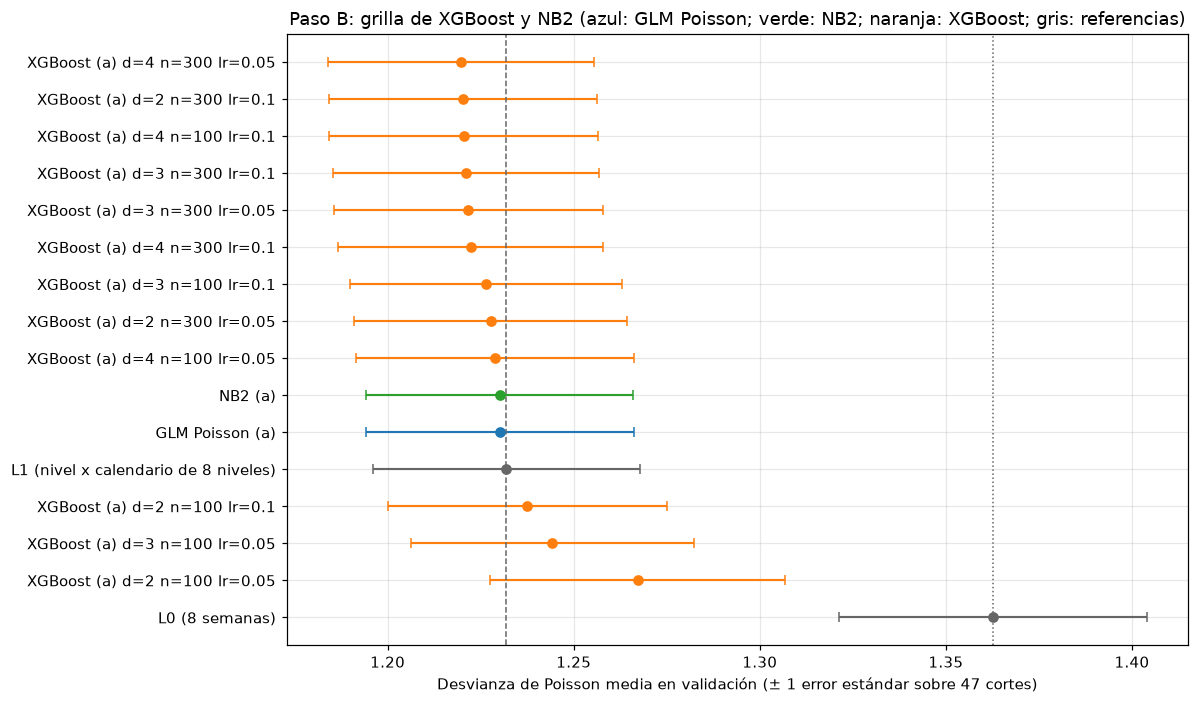

  guardado: experiments\modelos_candidatos\tablas\25_paso_b_predicciones.csv (34216 filas)


,configuracion,corte,origen,fecha,zona_id,n_siniestros,pred
0,NB2 (a),1,2024-03-14,2024-03-14,MUNICIPIO A,0,2.963655
1,NB2 (a),1,2024-03-14,2024-03-14,MUNICIPIO B,3,3.374218
2,NB2 (a),1,2024-03-14,2024-03-14,MUNICIPIO C,4,3.480553
3,NB2 (a),1,2024-03-14,2024-03-14,MUNICIPIO CH,1,2.096354
4,NB2 (a),1,2024-03-14,2024-03-14,MUNICIPIO D,3,3.256612
...,...,...,...,...,...,...,...
34211,XGBoost (a) d=4 n=300 lr=0.1,47,2025-01-30,2025-02-05,MUNICIPIO CH,3,2.292051
34212,XGBoost (a) d=4 n=300 lr=0.1,47,2025-01-30,2025-02-05,MUNICIPIO D,6,3.270097
34213,XGBoost (a) d=4 n=300 lr=0.1,47,2025-01-30,2025-02-05,MUNICIPIO E,6,2.241288
34214,XGBoost (a) d=4 n=300 lr=0.1,47,2025-01-30,2025-02-05,MUNICIPIO F,3,2.705660


In [22]:
# fig5: desvianza ± 1 EE de las configuraciones del paso B, con L1 y L0 de 8 semanas
fig, ax = plt.subplots(figsize=(11, 6.5))
t = glob_b.iloc[::-1]
y_pos = pd.Series(range(len(t)), index=t.index)
for fam, color in (("GLM Poisson", "C0"), ("NB2", "C2"), ("XGBoost", "C1"), ("referencia", "0.4")):
    f = t[t["familia"] == fam]
    ax.errorbar(f["desvianza"], y_pos[f.index], xerr=f["error_estandar"], fmt="o", color=color, elinewidth=1.4, capsize=3)
ax.set_yticks(range(len(t)), t["modelo"])
for nombre, ls in ((L1, "--"), ("L0 (8 semanas)", ":")):
    ax.axvline(t.loc[t["modelo"] == nombre, "desvianza"].iloc[0], color="0.4", ls=ls, lw=1)
ax.set_xlabel("Desvianza de Poisson media en validación (± 1 error estándar sobre 47 cortes)")
ax.set_title("Paso B: grilla de XGBoost y NB2 (azul: GLM Poisson; verde: NB2; naranja: XGBoost; gris: referencias)")
fig.tight_layout()
guardar_figura(fig, "fig5_paso_b_desvianza.png")
plt.show()

nuevas_b = [CONFIG_NB2] + CONFIGS_B_XGB                       # GLM Poisson (a) ya está en tablas/17
predicciones_b = pd.concat([PRED_CAND[c].assign(configuracion=c) for c in nuevas_b], ignore_index=True)
predicciones_b["origen"] = predicciones_b["origen"].dt.strftime("%Y-%m-%d")
predicciones_b["fecha"] = predicciones_b["fecha"].dt.strftime("%Y-%m-%d")
guardar_tabla(predicciones_b[["configuracion", "corte", "origen", "fecha", "zona_id", "n_siniestros", "pred"]].round(6),
              "25_paso_b_predicciones.csv")

### 8.1 Lectura del paso B

Cifras de `tablas/18` (globales), `21` (NB2 por corte), `22` (NB2 contra GLM Poisson), `23` (elección) y `24` (ajustes por corte).

**Evidencia**

- **NB2 (a) frente a GLM Poisson (a).** Desvianza 1,2301 contra 1,2302 (diferencia −0,000098; EE 0,0359 en los dos). NB2 gana en 27 de
  47 cortes. Las predicciones difieren como mucho en 0,0071 siniestros (0,18 % relativo). **α por máxima verosimilitud: de 0,0349 a
  0,0400, mediana 0,0377**. Los 47 ajustes convergieron en 4 iteraciones de Newton, sin avisos: **ningún corte usó el plan B**.
- **Familia GLM:** Poisson y NB2 empatan a menos de 1 EE (umbral 1,2660) y **D36 elige GLM Poisson (a)**.
- **Grilla de XGBoost.** Desvianza de 1,2197 (d=4, n=300, lr=0,05) a 1,2671 (d=2, n=100, lr=0,05). Umbral de 1 EE: 1,2555. Quedan
  dentro 11 de las 12 combinaciones; solo d=2, n=100, lr=0,05 queda afuera. Seis combinaciones quedan entre 1,2197 y 1,2223, y las de
  100 árboles con lr=0,05 son las peores de cada profundidad.
- **Familia XGBoost:** **D37 elige d=2, n=100, lr=0,1**, la única empatada con profundidad 2 y 100 árboles. Desvianza 1,2375 (EE
  0,0375). Es la décima de las doce, **queda por encima de L1 (+0,0056)** y le gana en 20 de 47 cortes. El paso 4 (D38) no intervino:
  el paso 3 dejó una sola configuración.
- **Control:** la combinación d=3, n=300, lr=0,05 reprodujo exactamente las predicciones de XGBoost (a) del paso A.
- 611 ajustes (13 configuraciones × 47 cortes), ninguno con avisos y ninguna predicción igual a 0.

**Inferencia**

- En validación, NB2 no cambia la predicción puntual: con α ≈ 0,04 la media estimada es casi la de Poisson. Es lo que la sección 1
  anticipaba: su papel son los intervalos y la inferencia sobre coeficientes, no la desvianza. La sobredispersión es moderada y
  coherente con la dispersión de Pearson del paso A (de 1,10 a 1,12).
- La grilla de XGBoost tiene una meseta: la mitad de las combinaciones queda a menos de 0,003 de la mejor. Entre las que quedan dentro
  de 1 EE, la regla elige la más simple, que **en desvianza media es peor que L1**, aunque esté a menos de 1 EE de ella. Es
  consecuencia directa de la regla fijada (1 EE amplio y simplicidad por D37), no un error del cálculo. El paso C usa esta
  configuración como «la mejor de XGBoost».

## 10. Estado y artefactos

- **Fase 1** (secciones 1 a 6): protocolo y referencias.
- **Fase 2, paso A** (sección 7): conjuntos de variables con GLM Poisson y XGBoost, ventana expansiva.
- **Fase 2, paso B** (sección 8): grilla de XGBoost y binomial negativa NB2 sobre el conjunto elegido en el paso A.
- **Pendiente:** paso C (sección 9: ventanas).
  La configuración final no se fija en este notebook todavía (fase 3).

El registro de experimentos está en `experiments/modelos_candidatos/registro_experimentos.csv`.

In [23]:
indice = pd.DataFrame(sorted([(f"tablas/{p.name}") for p in DIR_TABLAS.glob("*.csv") if p.name != "10_artefactos.csv"]
                             + [(f"figuras/{p.name}") for p in DIR_FIGURAS.glob("*.png")]
                             + ([RUTA_REGISTRO.name] if RUTA_REGISTRO.exists() else [])), columns=["artefacto"])
guardar_tabla(indice, "10_artefactos.csv")
indice

  guardado: experiments\modelos_candidatos\tablas\10_artefactos.csv (31 filas)


,artefacto
0,figuras/fig1_referencias_por_corte.png
1,figuras/fig2_referencias_por_municipio.png
2,figuras/fig3_total_semanal_referencias.png
3,figuras/fig4_paso_a_desvianza.png
4,figuras/fig5_paso_b_desvianza.png
5,registro_experimentos.csv
6,tablas/00_entorno.csv
7,tablas/01_verificacion_integridad.csv
8,tablas/02_particiones.csv
9,tablas/03_comprobacion_motor.csv
